# email-Eu-core: comunidades temporales e importancia estructural global

**Proyecto final — Redes Complexas (IC/UNICAMP).** Jesamin Zevallos Quispe y Percy Maldonado Quispe.

**Pregunta del proyecto:** ¿los cambios en la estructura comunitaria están asociados a cambios en la importancia estructural de los nodos, medida en **todo el grafo** de cada ventana?

Este notebook reemplaza la versión anterior y corrige tres problemas que impedían responder esa pregunta:

1. **Correspondencia de comunidades.** Antes, la cobertura se calculaba sobre el tamaño total de la comunidad, incluidos los usuarios que se fueron. Con una retención mensual de ~30–40 % el umbral era casi inalcanzable, y casi todo salía como "aparición/desaparición". Ahora la cobertura se calcula **solo sobre los miembros que siguen activos**. El abandono se reporta por separado.
2. **Medida de cambio comunitario.** `1 − Jaccard` tenía mediana ≈ 0,99 en todas las transiciones, una variable casi constante. Ahora, para cada usuario persistente, medimos **qué fracción de sus antiguos compañeros de comunidad (que siguen activos) sigue con él**.
3. **Inestabilidad de Louvain.** El ARI entre semillas era ≈ 0,6–0,7. Ahora corremos varias semillas, usamos la partición más representativa (medoide) y solo seguimos **comunidades robustas**.

Además, la sección 4 regenera el **GraphML** y recalcula las métricas de la entrega parcial **leyendo ese mismo archivo**, para que los números coincidan con lo que se entrega.

### Hipótesis que se ponen a prueba

| | Nivel | Pregunta medible | Medida | Signo esperado |
|---|---|---|---|---|
| **H1** | Comunidad | ¿Las comunidades más estables conservan a sus influenciadores? | Spearman parcial entre estabilidad de la comunidad y fracción de sus influenciadores (top 1 % PageRank global) que siguen en el top | + |
| **H2** | Usuario | ¿Los usuarios cuyo entorno comunitario se mantiene cambian menos su posición global? | Spearman parcial entre conservación de compañeros y \|Δ log PageRank\|, controlando grado (H2a) y además el solapamiento de vecinos directos (H2b) | − |
| **H3** | Evento | ¿Los usuarios cuya comunidad desaparece (H3a) o se divide/fusiona (H3b) cambian más su importancia que los de comunidades que continúan? | Wilcoxon pareado por transición sobre \|Δ log PageRank\| | mayor en eventos |

Cada asociación se compara con un **modelo nulo por permutación**. Un ρ aislado no dice nada; un ρ fuera de la distribución nula, sí. Resultados débiles o nulos también son resultados válidos. Asociación no implica causalidad.

**Ejecución:** Google Colab, de arriba hacia abajo. Las figuras se guardan en `resultados_emaileu/figuras/` (PNG listos para LaTeX) y las tablas en CSV.

## 1. Configuración y carga de datos

In [1]:
%pip install -q python-igraph plotly

import os, json, time, math, random, hashlib, platform, shutil
from pathlib import Path
from itertools import combinations
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

try:
    import igraph as ig
    ig.set_random_number_generator(random)
    BACKEND = "igraph"      # Louvain rápido (misma heurística de Blondel et al., 2008)
except ImportError:
    ig = None
    BACKEND = "networkx"    # funciona igual, pero más lento

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})
AZUL, VERDE, LILA, GRIS, NARANJA = "#4e79a7", "#59a14f", "#8b78b0", "#9a9a9a", "#e08b3a"

print("Backend de comunidades:", BACKEND)
print("NetworkX:", nx.__version__, "| pandas:", pd.__version__)
tiempos = {}

Backend de comunidades: igraph
NetworkX: 3.7 | pandas: 2.2.3


In [2]:
# ================= CONFIGURACIÓN: EMAIL-EU-CORE (TEMPORAL) =================
NOMBRE_RED = "email-Eu-core"
PREFIJO = "emaileu"
URL = "https://snap.stanford.edu/data/email-Eu-core-temporal.txt.gz"
URL_NOMBRES = None
EXCLUIR_BOTS = False
# Red estática con los departamentos (verdad de referencia) para la sección 9b
URL_ESTATICA = "https://snap.stanford.edu/data/email-Eu-core.txt.gz"
URL_ETIQUETAS = "https://snap.stanford.edu/data/email-Eu-core-department-labels.txt.gz"
ARCHIVO = Path("email-Eu-core-temporal.txt.gz")

# Los timestamps son segundos desde el inicio de la recolección (803 días): las fechas
# aparecen como 1970–1972 y significan TIEMPO TRANSCURRIDO. None = meses completos observados.
INICIO = pd.Timestamp("1970-01-01", tz="UTC")
FIN = pd.Timestamp("1971-01-01", tz="UTC")    # exclusivo
MUESTRA_DISTANCIAS = 986                       # red pequeña: distancias exactas desde todas las fuentes

# ---- Preprocesamiento ----
MINIMO_PARTICIPACIONES = 3          # una sola vez sobre todo el período

# ---- Ventanas temporales (sección 5) ----
DURACIONES_CANDIDATAS = [1, 2, 3, 6]  # meses, ventanas no superpuestas
VENTANA_MESES = None                 # None = usar la duración sugerida por la regla de la sección 5
MIN_TRANSICIONES = 10

# ---- Comunidades ----
SEMILLAS = [42, 7, 21, 1, 99]        # Louvain; se usa la partición medoide
SEMILLAS_TRADEOFF = [42, 7]          # menos semillas para comparar duraciones (más rápido)
SEMILLAS_ALTERNATIVAS = [3, 11, 2024]  # sensibilidad
RESOLUCION = 1.0
MINIMO_COMUNIDAD = 10                # tamaño mínimo para seguir una comunidad
UMBRAL_ROBUSTEZ = 0.5                # robustez media mínima entre semillas

# ---- Correspondencia y eventos ----
MINIMO_COMPARTIDOS = 3
UMBRAL_COBERTURA = 0.5               # sobre usuarios PERSISTENTES; ≥ 0,5 da sucesores únicos por lado
UMBRAL_CAMBIO = 0.10                 # ±10 % separa crecimiento/contracción de "estable"

# ---- Importancia global ----
FRACCION_INFLUENCIADORES = 0.01      # top 1 % de PageRank global de cada ventana
MINIMO_INFLUENCIADORES = 20
CALCULAR_BETWEENNESS = True
MUESTRA_BETWEENNESS = 64             # fuentes muestreadas (aproximación)

# ---- Estadística ----
N_PERMUTACIONES = 200
SEMILLA_GENERAL = 42
USUARIOS_EXCLUIR_SENSIBILIDAD = None  # None = detectar automáticamente (≥ 1 % de los eventos o nombre con "bot")
SENSIBILIDAD_SIN_FILTRO = True
GUARDAR_GRAPHML_VENTANAS = True      # un GraphML comprimido por ventana (con comunidad y PageRank)

# ---- Ajustes para una red pequeña (~1.000 personas) ----
MINIMO_INFLUENCIADORES = 10          # top 1 % sería ~6 personas; usamos al menos 10
USUARIOS_EXCLUIR_SENSIBILIDAD = []   # no hay bots; los usuarios muy activos son personas reales

In [3]:
CARPETA = Path(f"resultados_{PREFIJO}")
FIGURAS = CARPETA / "figuras"
GRAPHML = CARPETA / "graphml"
for carpeta in (CARPETA, FIGURAS, GRAPHML):
    carpeta.mkdir(parents=True, exist_ok=True)

rng_global = np.random.default_rng(SEMILLA_GENERAL)

def guardar_figura(fig, nombre):
    """Guarda la figura en PNG para el informe en LaTeX."""
    fig.savefig(FIGURAS / f"{nombre}.png", bbox_inches="tight")

if not ARCHIVO.exists():
    ARCHIVO = Path(URL.split("/")[-1])
    if not ARCHIVO.exists():
        print("Descargando", URL)
        urlretrieve(URL, ARCHIVO)
print("Archivo:", ARCHIVO, "|", round(ARCHIVO.stat().st_size / 1e6, 1), "MB")

Descargando https://snap.stanford.edu/data/email-Eu-core-temporal.txt.gz
Archivo: email-Eu-core-temporal.txt.gz | 1.7 MB


In [4]:
datos_originales = pd.read_csv(
    ARCHIVO, sep=r"\s+", comment="#", header=None,
    names=["source", "target", "timestamp"],
    dtype={"source": "int64", "target": "int64", "timestamp": "int64"},
)
datos_originales["fecha"] = pd.to_datetime(datos_originales["timestamp"], unit="s", utc=True)
if datos_originales.timestamp.min() < 10**8:
    print("Aviso: los timestamps parecen relativos (segundos desde el inicio). "
          "Las fechas de 1970 indican tiempo transcurrido, no fechas reales.")
# INICIO/FIN = None → primer y último mes completos observados
if INICIO is None:
    INICIO = datos_originales.fecha.min().normalize().replace(day=1)
if FIN is None:
    FIN = datos_originales.fecha.max().normalize().replace(day=1)
print("Período de análisis:", INICIO.date(), "→", FIN.date(), "(exclusivo)")

usuarios_originales = np.union1d(datos_originales.source, datos_originales.target)
resumen_carga = pd.DataFrame({
    "medida": ["Eventos registrados", "Usuarios distintos", "Primera fecha", "Última fecha"],
    "valor": [len(datos_originales), len(usuarios_originales),
              datos_originales.fecha.min(), datos_originales.fecha.max()],
})
display(resumen_carga)

Aviso: los timestamps parecen relativos (segundos desde el inicio). Las fechas de 1970 indican tiempo transcurrido, no fechas reales.
Período de análisis: 1970-01-01 → 1971-01-01 (exclusivo)


,medida,valor
0,Eventos registrados,332334
1,Usuarios distintos,986
2,Primera fecha,1970-01-01 00:00:00+00:00
3,Última fecha,1972-03-14 22:14:14+00:00


## 2. Diagnóstico inicial

Revisamos valores faltantes, autointeracciones y repeticiones exactas, la actividad mensual (para justificar el período) y los usuarios con actividad atípica. Estos últimos pueden ser bots o cuentas de mensajes masivos, y se usan en la sensibilidad.

,revisión,cantidad,% de eventos
0,Filas con valores faltantes,0,0.0
1,Autointeracciones,0,0.0
2,Repeticiones exactas adicionales,4998,1.5


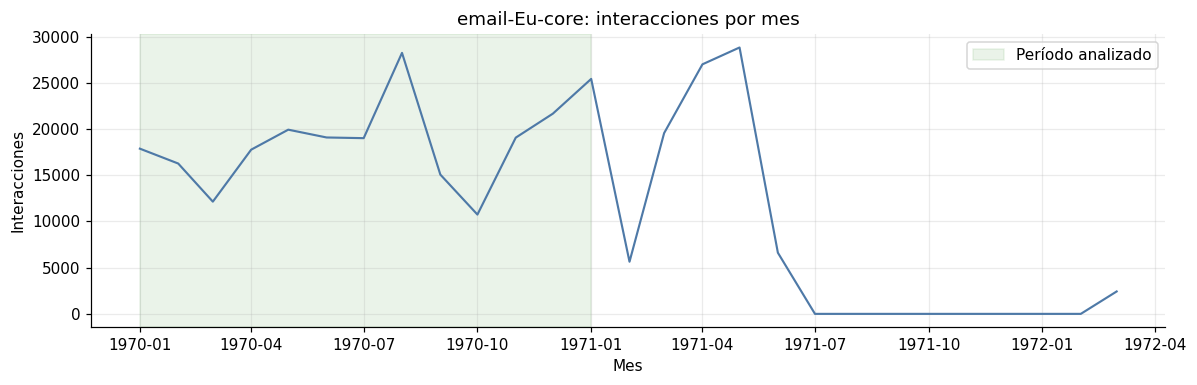

In [5]:
es_auto = datos_originales.source.eq(datos_originales.target)
es_repetido = datos_originales.duplicated(["source", "target", "timestamp"])
revision = pd.DataFrame({
    "revisión": ["Filas con valores faltantes", "Autointeracciones", "Repeticiones exactas adicionales"],
    "cantidad": [int(datos_originales.isna().any(axis=1).sum()), int(es_auto.sum()), int(es_repetido.sum())],
})
revision["% de eventos"] = (100 * revision["cantidad"] / len(datos_originales)).round(2)
display(revision)

mensual = datos_originales.set_index("fecha").resample("MS").size()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(mensual.index, mensual.values, color=AZUL, lw=1.4)
ax.axvspan(INICIO, FIN, color=VERDE, alpha=0.12, label="Período analizado")
ax.set(title=f"{NOMBRE_RED}: interacciones por mes", xlabel="Mes", ylabel="Interacciones")
ax.legend()
plt.tight_layout(); guardar_figura(fig, "fig01_actividad_mensual"); plt.show()

## 3. Preprocesamiento

1. Seleccionar el período de estudio `[INICIO, FIN)`.
2. Eliminar autointeracciones (no son relaciones entre usuarios).
3. Si `EXCLUIR_BOTS = True` y la base trae nombres de usuario (WikiTalk), eliminar las cuentas automáticas. Una cuenta se considera bot si su nombre contiene "bot" como palabra o sufijo (p. ej. `SineBot`, `MiszaBot_III`) **y** envía al menos 5 veces más mensajes de los que recibe. Los bots no representan interacción social, pero crean estrellas enormes que distorsionan las comunidades. El análisis **con** bots queda en la sensibilidad.
4. Conservar usuarios con al menos `MINIMO_PARTICIPACIONES` participaciones (enviadas o recibidas) en el período. El filtro se aplica **una sola vez** y quedan los eventos entre usuarios conservados.

Se mantienen las fechas individuales y las repeticiones: el peso de una arista es el número de interacciones en la ventana. El filtro sesga el análisis hacia usuarios más activos; su efecto se evalúa en la sensibilidad.

In [6]:
import re, gzip

def cargar_nombres(url):
    nombres = {}
    if not url:
        return nombres
    try:
        ruta = Path(url.split("/")[-1])
        if not ruta.exists():
            urlretrieve(url, ruta)
        abrir = gzip.open if ruta.suffix == ".gz" else open
        with abrir(ruta, "rt", encoding="utf-8", errors="replace") as f:
            for linea in f:
                partes = linea.strip().split(maxsplit=1)
                if len(partes) == 2 and partes[0].lstrip("-").isdigit():
                    nombres[int(partes[0])] = partes[1]
        print(f"Nombres cargados: {len(nombres):,}")
    except Exception as error:
        print("No se pudieron cargar los nombres de usuario:", error)
    return nombres

nombres = cargar_nombres(URL_NOMBRES)

datos_periodo = datos_originales.loc[datos_originales.fecha.ge(INICIO) & datos_originales.fecha.lt(FIN)]
base_con_bots = datos_periodo.loc[datos_periodo.source.ne(datos_periodo.target)].copy()

PATRON_BOT = re.compile(r"[Bb]ot(?![a-z])|BOT")
bots = []
if nombres:
    enviados = base_con_bots.source.value_counts(); recibidos = base_con_bots.target.value_counts()
    bots = sorted(u for u, n in nombres.items()
                  if PATRON_BOT.search(n) and enviados.get(u, 0) >= 5 * max(recibidos.get(u, 0), 1))
    print(f"Cuentas identificadas como bots: {len(bots)}")
    display(pd.DataFrame({"usuario": bots, "nombre": [nombres[u] for u in bots],
                          "enviados": [int(enviados.get(u, 0)) for u in bots]})
            .sort_values("enviados", ascending=False).head(15))
if EXCLUIR_BOTS and bots:
    base_analisis = base_con_bots.loc[~base_con_bots.source.isin(bots) & ~base_con_bots.target.isin(bots)].copy()
else:
    base_analisis = base_con_bots

participaciones = pd.concat([base_analisis.source, base_analisis.target]).value_counts()

def filtrar_actividad(eventos, minimo):
    conteo = pd.concat([eventos.source, eventos.target]).value_counts()
    seleccion = conteo.index[conteo.ge(minimo)]
    filtrado = eventos.loc[eventos.source.isin(seleccion) & eventos.target.isin(seleccion)]
    return filtrado.sort_values("fecha", kind="stable").reset_index(drop=True)

datos_limpios = filtrar_actividad(base_analisis, MINIMO_PARTICIPACIONES)

def resumir_etapa(eventos, etapa):
    return {"etapa": etapa,
            "usuarios": len(np.union1d(eventos.source, eventos.target)),
            "eventos": len(eventos)}

resumen_preprocesamiento = pd.DataFrame([
    resumir_etapa(datos_originales, "Dataset original"),
    resumir_etapa(datos_periodo, f"Período {INICIO:%Y-%m}–{FIN - pd.Timedelta(days=1):%Y-%m}"),
    resumir_etapa(base_con_bots, "Sin autointeracciones"),
    *([resumir_etapa(base_analisis, f"Sin {len(bots)} bots")] if EXCLUIR_BOTS and bots else []),
    resumir_etapa(datos_limpios, f"Filtro ≥ {MINIMO_PARTICIPACIONES} participaciones"),
])
display(resumen_preprocesamiento)

,etapa,usuarios,eventos
0,Dataset original,986,332334
1,Período 1970-01–1970-12,891,216852
2,Sin autointeracciones,891,216852
3,Filtro ≥ 3 participaciones,833,216775


In [7]:
# Usuarios con actividad atípica: ≥ 1 % de todos los eventos limpios.
# No se eliminan en el análisis principal; se usan en la sensibilidad (sección 14).
salidas = datos_limpios.source.value_counts()
entradas = datos_limpios.target.value_counts()
actividad = pd.DataFrame({"enviadas": salidas, "recibidas": entradas}).fillna(0).astype(int)
actividad["total"] = actividad.enviadas + actividad.recibidas
actividad["% de eventos"] = 100 * actividad.total / len(datos_limpios)
actividad = actividad.sort_values("total", ascending=False)

actividad["nombre"] = actividad.index.map(lambda u: nombres.get(u, ""))
display(actividad.head(10).round(2))

if USUARIOS_EXCLUIR_SENSIBILIDAD is None:
    USUARIOS_EXCLUIR_SENSIBILIDAD = sorted(actividad.index[actividad["% de eventos"].ge(1.0)])
print("Usuarios atípicos para la sensibilidad:", USUARIOS_EXCLUIR_SENSIBILIDAD)

,enviadas,recibidas,total,% de eventos,nombre
629,5054,1820,6874,3.17,
168,3397,2797,6194,2.86,
987,5637,554,6191,2.86,
586,3634,1919,5553,2.56,
356,3018,1706,4724,2.18,
98,3319,965,4284,1.98,
178,3499,590,4089,1.89,
915,2308,1571,3879,1.79,
746,2920,957,3877,1.79,
947,1688,2038,3726,1.72,


Usuarios atípicos para la sensibilidad: []


## 4. Red agregada en GraphML y análisis estructural (corrige la entrega parcial)

Observaciones del profesor sobre la entrega parcial: faltaba un GraphML, las métricas no coincidían con el archivo y "grado medio dirigido" no es un concepto válido. Aquí:

- Se construye la red agregada del período (dirigida y ponderada, con la primera y última fecha de cada arista) y se guarda en **GraphML**.
- **Todas las métricas se calculan leyendo ese mismo archivo.** Así la tabla coincide con lo entregado.
- Grado medio: en el grafo dirigido, ⟨k_in⟩ = ⟨k_out⟩ = E/N. En la versión no dirigida, ⟨k⟩ = 2E/N.
- Clustering: **transitividad** (global, triángulos) y **clustering medio** (promedio de los coeficientes locales; nodos con grado < 2 cuentan como 0).
- Distancia media y diámetro en la componente gigante, con BFS desde una muestra de fuentes. El diámetro es un **límite inferior** obtenido por barridos dobles.

In [8]:
inicio_etapa = time.perf_counter()
aristas_estaticas = (
    datos_limpios.groupby(["source", "target"])
    .agg(weight=("timestamp", "size"), primer_ts=("timestamp", "min"), ultimo_ts=("timestamp", "max"))
    .reset_index()
)
G_agregado = nx.DiGraph(red=NOMBRE_RED, periodo=f"{INICIO:%Y-%m-%d} a {FIN:%Y-%m-%d} (exclusivo)",
                        minimo_participaciones=MINIMO_PARTICIPACIONES)
G_agregado.add_edges_from(
    (int(s), int(t), {"weight": int(w), "primer_ts": int(a), "ultimo_ts": int(b)})
    for s, t, w, a, b in aristas_estaticas.itertuples(index=False)
)
RUTA_GRAPHML = GRAPHML / f"{PREFIJO}_{INICIO:%Y}_{(FIN - pd.Timedelta(days=1)):%Y}.graphml"
nx.write_graphml(G_agregado, RUTA_GRAPHML)
print("GraphML:", RUTA_GRAPHML, "|", round(RUTA_GRAPHML.stat().st_size / 1e6, 1), "MB")

# Se vuelve a leer el archivo para que las métricas correspondan exactamente a lo entregado.
G_archivo = nx.read_graphml(RUTA_GRAPHML, node_type=int)
del G_agregado

GraphML: resultados_emaileu/graphml/emaileu_1970_1970.graphml | 2.5 MB


In [9]:
def triangulos_por_nodo(G):
    """Triángulos por nodo en un grafo simple no dirigido, en O(sum min(d_u, d_v)).
    Evita la implementación de NetworkX, que es muy lenta con hubs de grado alto."""
    vecinos = {n: set(G[n]) - {n} for n in G}
    tri = dict.fromkeys(G, 0)
    for u, v in G.edges():
        if u == v:
            continue
        c = len(vecinos[u] & vecinos[v])
        tri[u] += c
        tri[v] += c
    return {n: t // 2 for n, t in tri.items()}


def distancias_muestreadas(G, n_fuentes, semilla):
    rng = np.random.default_rng(semilla)
    nodos = np.array(list(G.nodes()))
    fuentes = rng.choice(nodos, size=min(n_fuentes, len(nodos)), replace=False)
    suma, pares, diametro, mas_lejano = 0, 0, 0, None
    for s in fuentes:
        d = nx.single_source_shortest_path_length(G, s)
        valores = np.fromiter(d.values(), dtype=np.int64)
        suma += valores.sum(); pares += len(valores) - 1
        if valores.max() > diametro:
            diametro = int(valores.max()); mas_lejano = max(d, key=d.get)
    # barridos dobles: BFS desde el nodo más lejano encontrado (límite inferior del diámetro)
    for _ in range(4):
        d = nx.single_source_shortest_path_length(G, mas_lejano)
        mas_lejano = max(d, key=d.get)
        diametro = max(diametro, d[mas_lejano])
    return suma / pares, diametro, len(fuentes)


def metricas_estructurales(Gd):
    N, Ed = Gd.number_of_nodes(), Gd.number_of_edges()
    Gu = nx.Graph(); Gu.add_nodes_from(Gd); Gu.add_edges_from(Gd.edges())
    Gu.remove_edges_from(list(nx.selfloop_edges(Gu)))
    Eu = Gu.number_of_edges()
    grados = dict(Gu.degree())
    tri = triangulos_por_nodo(Gu)
    pares_conectados = {n: grados[n] * (grados[n] - 1) / 2 for n in Gu}
    clustering_local = pd.Series({n: (tri[n] / pares_conectados[n]) if grados[n] >= 2 else 0.0 for n in Gu})
    transitividad = sum(tri.values()) / sum(pares_conectados.values())
    componentes = sorted((len(c) for c in nx.connected_components(Gu)), reverse=True)
    gigante = Gu.subgraph(max(nx.connected_components(Gu), key=len))
    dist_media, diametro, fuentes = distancias_muestreadas(gigante, MUESTRA_DISTANCIAS, SEMILLA_GENERAL)
    tabla = pd.DataFrame({"métrica": [
        "Vértices (N)", "Arestas dirigidas (E)", "Arestas não dirigidas",
        "Grau médio de entrada = saída (E/N)", "Grau médio não dirigido (2E/N)",
        "Clustering médio (média dos coeficientes locais)", "Transitividade (clustering global)",
        f"Distância média na componente gigante (aprox., {fuentes} fontes)",
        "Diâmetro da componente gigante (limite inferior)",
        "Densidade não dirigida 2E/(N(N−1))", "Densidade dirigida E/(N(N−1))",
        "Número de componentes conexas", "Tamanho da maior componente", "Maior componente (% dos vértices)",
    ], "valor": [
        N, Ed, Eu, Ed / N, 2 * Eu / N,
        clustering_local.mean(), transitividad, dist_media, diametro,
        2 * Eu / (N * (N - 1)), Ed / (N * (N - 1)),
        len(componentes), componentes[0], 100 * componentes[0] / N,
    ]})
    return tabla, Gu, clustering_local, pd.Series(grados), componentes

tabla_estatica, G_no_dirigido, clustering_local, grados_estaticos, tamanos_componentes = metricas_estructurales(G_archivo)
pd.set_option("display.float_format", lambda v: f"{v:,.6g}")
display(tabla_estatica)
tabla_estatica.to_csv(CARPETA / "tabla_metricas_graphml.csv", index=False)
tiempos["estatico"] = time.perf_counter() - inicio_etapa

,métrica,valor
0,Vértices (N),833
1,Arestas dirigidas (E),"19,145"
2,Arestas não dirigidas,"12,390"
3,Grau médio de entrada = saída (E/N),22.9832
4,Grau médio não dirigido (2E/N),29.7479
5,Clustering médio (média dos coeficientes locais),0.414158
6,Transitividade (clustering global),0.258205
7,"Distância média na componente gigante (aprox.,...",2.53671
8,Diâmetro da componente gigante (limite inferior),6
9,Densidade não dirigida 2E/(N(N−1)),0.0357547


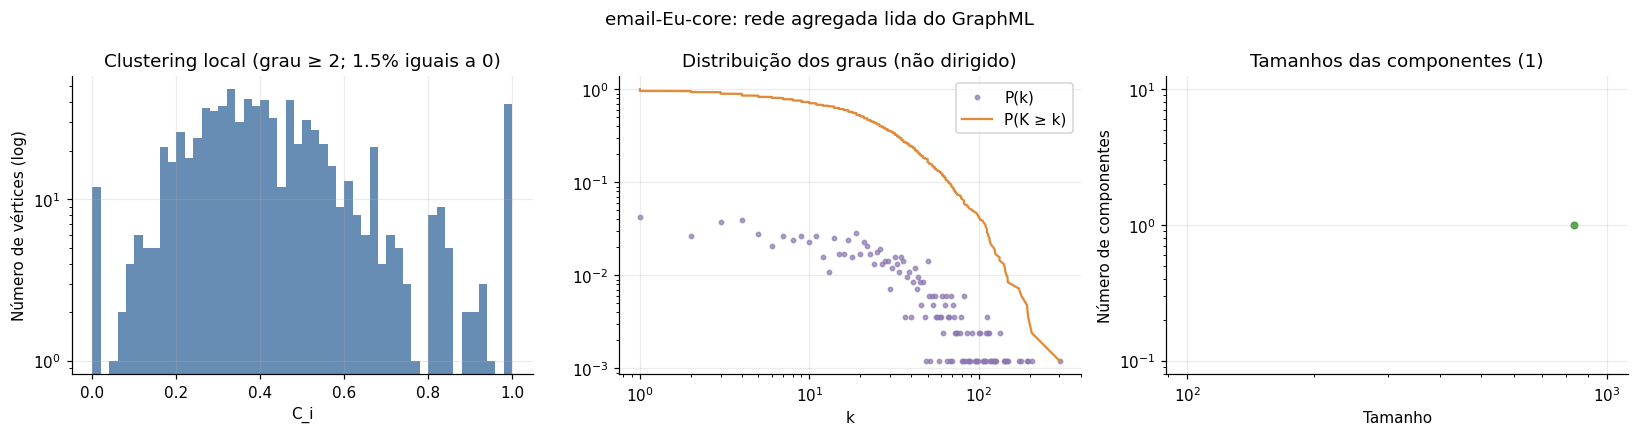

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

con_grado = clustering_local[grados_estaticos.reindex(clustering_local.index) >= 2]
axes[0].hist(con_grado, bins=50, color=AZUL, alpha=0.85)
axes[0].set_yscale("log")
axes[0].set(title=f"Clustering local (grau ≥ 2; {100 * (con_grado == 0).mean():.1f}% iguais a 0)",
            xlabel="C_i", ylabel="Número de vértices (log)")

valores, conteos = np.unique(grados_estaticos.values, return_counts=True)
positivos = valores > 0
axes[1].scatter(valores[positivos], conteos[positivos] / conteos.sum(), s=8, color=LILA, alpha=0.7, label="P(k)")
ordenado = np.sort(grados_estaticos.values)
ccdf = 1 - np.arange(len(ordenado)) / len(ordenado)
axes[1].plot(ordenado, ccdf, color=NARANJA, lw=1.5, label="P(K ≥ k)")
axes[1].set(xscale="log", yscale="log", title="Distribuição dos graus (não dirigido)", xlabel="k")
axes[1].legend()

tam, cnt = np.unique(tamanos_componentes, return_counts=True)
axes[2].scatter(tam, cnt, color=VERDE, s=18)
axes[2].set(xscale="log", yscale="log", title=f"Tamanhos das componentes ({len(tamanos_componentes):,})",
            xlabel="Tamanho", ylabel="Número de componentes")
fig.suptitle(f"{NOMBRE_RED}: rede agregada lida do GraphML")
plt.tight_layout(); guardar_figura(fig, "fig02_distribuciones_estaticas"); plt.show()
del G_archivo, G_no_dirigido

## 5. Elección del tamaño de ventana (observación del profesor)

No existe una ventana "correcta". Ventanas cortas dan más resolución temporal, pero grafos ralos y comunidades ruidosas; ventanas largas dan más estabilidad, pero menos transiciones y mezclan cambios. Comparamos ventanas **no superpuestas** de varias duraciones con cuatro criterios:

- **Retención:** fracción de usuarios de la ventana *t* que siguen activos en *t+1*.
- **ARI entre semillas:** confiabilidad de la partición *dentro* de una ventana.
- **ARI temporal:** concordancia entre las particiones de *t* y *t+1*, calculada solo sobre usuarios persistentes. Mide continuidad estructural sin el efecto del abandono.
- **% de comunidades robustas con correspondencia** en *t+1*.

No usamos ventanas deslizantes (superpuestas): dos ventanas que comparten datos parecen estables de forma artificial.

**Regla explícita:** entre las duraciones con al menos `MIN_TRANSICIONES` transiciones, elegimos la de mayor ARI temporal mediano (en caso de empate, la más corta). La regla se puede sustituir fijando `VENTANA_MESES` en la configuración.

In [11]:
def ventanas_fijas(inicio, fin, meses):
    ventanas, a = [], inicio
    while a + pd.DateOffset(months=meses) <= fin:
        b = a + pd.DateOffset(months=meses)
        ventanas.append((a, b))
        a = b
    return ventanas


def eventos_en(datos, a, b):
    return datos.iloc[datos.fecha.searchsorted(a): datos.fecha.searchsorted(b)]


def construir_grafos(eventos):
    """Grafo dirigido ponderado (importancia) y no dirigido ponderado (comunidades)."""
    dirigidas = eventos.groupby(["source", "target"]).size().reset_index(name="weight")
    Gd = nx.from_pandas_edgelist(dirigidas, "source", "target", "weight", create_using=nx.DiGraph)
    no_dirigidas = (
        dirigidas.assign(u=np.minimum(dirigidas.source, dirigidas.target),
                         v=np.maximum(dirigidas.source, dirigidas.target))
        .groupby(["u", "v"], as_index=False)["weight"].sum()
    )
    Gu = nx.from_pandas_edgelist(no_dirigidas, "u", "v", "weight")
    return Gd, Gu, no_dirigidas


def particiones_louvain(Gu, no_dirigidas, semillas):
    """Louvain con varias semillas. Devuelve los nodos ordenados, una lista de etiquetas
    (una por semilla) y una función para calcular la modularidad de una partición."""
    global BACKEND
    if BACKEND == "igraph":
        try:
            return _louvain_igraph(Gu, no_dirigidas, semillas)
        except Exception as error:
            print("igraph falló; se usa NetworkX:", error)
            BACKEND = "networkx"
    return _louvain_networkx(Gu, semillas)


def _louvain_igraph(Gu, no_dirigidas, semillas):
    nodos = np.array(sorted(Gu.nodes()))
    if True:
        indice = pd.Series(np.arange(len(nodos)), index=nodos)
        aristas = list(zip(indice[no_dirigidas.u].tolist(), indice[no_dirigidas.v].tolist()))
        gi = ig.Graph(n=len(nodos), edges=aristas,
                      edge_attrs={"weight": no_dirigidas.weight.astype(float).tolist()})
        etiquetas = []
        for s in semillas:
            random.seed(s)
            etiquetas.append(np.array(gi.community_multilevel(weights="weight", resolution=RESOLUCION).membership))
        def modularidad(et):
            return gi.modularity(list(map(int, et)), weights="weight", resolution=RESOLUCION)
    return nodos, etiquetas, modularidad


def _louvain_networkx(Gu, semillas):
    nodos = np.array(sorted(Gu.nodes()))
    if True:
        posicion = {n: i for i, n in enumerate(nodos)}
        etiquetas = []
        for s in semillas:
            et = np.empty(len(nodos), dtype=int)
            for c, grupo in enumerate(nx.community.louvain_communities(Gu, weight="weight", resolution=RESOLUCION, seed=s)):
                et[[posicion[n] for n in grupo]] = c
            etiquetas.append(et)
        def modularidad(et):
            grupos = pd.Series(nodos).groupby(et).apply(set).tolist()
            return nx.community.modularity(Gu, grupos, weight="weight", resolution=RESOLUCION)
    return nodos, etiquetas, modularidad


def resumir_particiones(nodos, etiquetas):
    """Partición medoide (mayor ARI medio con las demás), renumerada por tamaño, y robustez de cada nodo:
    fracción de su comunidad que sigue con él en las otras semillas (promediada)."""
    R = len(etiquetas)
    ari = []
    if R > 1:
        M = np.ones((R, R))
        for a, b in combinations(range(R), 2):
            M[a, b] = M[b, a] = adjusted_rand_score(etiquetas[a], etiquetas[b])
            ari.append(M[a, b])
        medoide = int(np.argmax(M.sum(axis=1)))
    else:
        medoide = 0
    base = pd.Series(etiquetas[medoide])
    tamanos = base.value_counts()
    orden = {c: i for i, c in enumerate(sorted(tamanos.index, key=lambda c: (-tamanos[c], c)))}
    comunidad = base.map(orden).to_numpy()

    robustez = np.zeros(len(nodos))
    otras = [e for i, e in enumerate(etiquetas) if i != medoide]
    for e in otras:
        df = pd.DataFrame({"c": comunidad, "l": e})
        robustez += (df.groupby(["c", "l"])["c"].transform("size") / df.groupby("c")["c"].transform("size")).to_numpy()
    robustez = robustez / len(otras) if otras else np.ones(len(nodos))

    asignacion = pd.DataFrame({"usuario": nodos, "comunidad": comunidad, "robustez_nodo": robustez})
    comunidades = (asignacion.groupby("comunidad")
                   .agg(tamano=("usuario", "size"), robustez=("robustez_nodo", "mean")).reset_index())
    comunidades["robusta"] = comunidades.tamano.ge(MINIMO_COMUNIDAD) & comunidades.robustez.ge(UMBRAL_ROBUSTEZ)
    return asignacion, comunidades, ari


def correspondencias(asig_a, asig_b, com_a, com_b):
    """Solapamiento entre comunidades de t y t+1, con cobertura calculada SOLO sobre los usuarios persistentes."""
    comunes = asig_a[["usuario", "comunidad"]].merge(asig_b[["usuario", "comunidad"]], on="usuario", suffixes=("_a", "_b"))
    persistentes_a = comunes.groupby("comunidad_a").size()
    persistentes_b = comunes.groupby("comunidad_b").size()
    pares = comunes.groupby(["comunidad_a", "comunidad_b"]).size().reset_index(name="compartidos")
    pares["persistentes_a"] = pares.comunidad_a.map(persistentes_a)
    pares["persistentes_b"] = pares.comunidad_b.map(persistentes_b)
    pares["cobertura_a"] = pares.compartidos / pares.persistentes_a
    pares["cobertura_b"] = pares.compartidos / pares.persistentes_b
    pares["jaccard_persistente"] = pares.compartidos / (pares.persistentes_a + pares.persistentes_b - pares.compartidos)
    robustas_a = set(com_a.comunidad[com_a.robusta]); robustas_b = set(com_b.comunidad[com_b.robusta])
    pares["ambas_robustas"] = pares.comunidad_a.isin(robustas_a) & pares.comunidad_b.isin(robustas_b)
    return pares, comunes, persistentes_a


def identificar_eventos(pares, com_a, com_b, persistentes_a, umbral):
    """Clasifica cada componente del grafo bipartito de correspondencias:
    1→1 continuación (crecimiento/contracción/estable), 1→N división, N→1 fusión,
    N→N reorganización, 1→0 desaparición, 0→1 aparición."""
    enlaces = pares.loc[pares.ambas_robustas & pares.compartidos.ge(MINIMO_COMPARTIDOS)
                        & (pares.cobertura_a.ge(umbral) | pares.cobertura_b.ge(umbral))]
    tam_a = com_a.set_index("comunidad").tamano; tam_b = com_b.set_index("comunidad").tamano
    B = nx.Graph()
    B.add_nodes_from(("a", int(c)) for c in com_a.comunidad[com_a.robusta])
    B.add_nodes_from(("b", int(c)) for c in com_b.comunidad[com_b.robusta])
    B.add_edges_from((("a", int(r.comunidad_a)), ("b", int(r.comunidad_b))) for r in enlaces.itertuples())
    filas, evento_de_a = [], {}
    for k, comp in enumerate(sorted(nx.connected_components(B), key=lambda c: min(c))):
        A = sorted(c for lado, c in comp if lado == "a"); Bs = sorted(c for lado, c in comp if lado == "b")
        ua, ub = int(tam_a.reindex(A).sum()), int(tam_b.reindex(Bs).sum())
        cambio = (ub - ua) / ua if A and Bs else np.nan
        if A and Bs:
            if len(A) == 1 and len(Bs) == 1:
                tipo = "Crecimiento" if cambio > UMBRAL_CAMBIO else "Contracción" if cambio < -UMBRAL_CAMBIO else "Estable"
            elif len(A) == 1:
                tipo = "División"
            elif len(Bs) == 1:
                tipo = "Fusión"
            else:
                tipo = "Reorganización"
        elif A:
            tipo = "Desaparición"
        else:
            tipo = "Aparición"
        retencion = (persistentes_a.reindex(A).fillna(0).sum() / ua) if A else np.nan
        filas.append({"evento": k, "tipo": tipo, "comunidades_a": A, "comunidades_b": Bs,
                      "usuarios_a": ua, "usuarios_b": ub, "cambio_tamano": cambio,
                      "retencion_miembros_a": retencion})
        for c in A:
            evento_de_a[c] = (k, tipo)
    columnas = ["evento", "tipo", "comunidades_a", "comunidades_b", "usuarios_a", "usuarios_b",
                "cambio_tamano", "retencion_miembros_a"]
    eventos = pd.DataFrame(filas, columns=columnas).astype(
        {"evento": "int64", "usuarios_a": "int64", "usuarios_b": "int64",
         "cambio_tamano": "float64", "retencion_miembros_a": "float64"})
    return enlaces, eventos, evento_de_a

In [12]:
def resumen_basico(Gd, Gu, eventos):
    componentes = [len(c) for c in nx.connected_components(Gu)]
    N = Gu.number_of_nodes()
    return {"interacciones": len(eventos), "usuarios": N,
            "aristas_dirigidas": Gd.number_of_edges(), "aristas_no_dirigidas": Gu.number_of_edges(),
            "grado_medio_no_dirigido": 2 * Gu.number_of_edges() / N if N else np.nan,
            "componentes": len(componentes),
            "pct_mayor_componente": 100 * max(componentes) / N if N else np.nan}


def evaluar_duracion(datos, meses, semillas):
    ventanas = ventanas_fijas(INICIO, FIN, meses)
    estados, filas_v, filas_t = [], [], []
    for a, b in ventanas:
        ev = eventos_en(datos, a, b)
        Gd, Gu, nd = construir_grafos(ev)
        nodos, etiquetas, _ = particiones_louvain(Gu, nd, semillas)
        asig, com, ari = resumir_particiones(nodos, etiquetas)
        estados.append((asig, com))
        filas_v.append({"inicio": a, **resumen_basico(Gd, Gu, ev),
                        "ari_semillas": np.median(ari) if ari else np.nan})
    for t in range(len(estados) - 1):
        (asig_a, com_a), (asig_b, com_b) = estados[t], estados[t + 1]
        pares, comunes, pers_a = correspondencias(asig_a, asig_b, com_a, com_b)
        enlaces, ev, _ = identificar_eventos(pares, com_a, com_b, pers_a, UMBRAL_COBERTURA)
        robustas = com_a.robusta.sum()
        con_corr = ev.loc[ev.comunidades_a.str.len().gt(0) & ev.comunidades_b.str.len().gt(0), "comunidades_a"].str.len().sum()
        filas_t.append({"retencion": len(comunes) / len(asig_a),
                        "ari_temporal": adjusted_rand_score(comunes.comunidad_a, comunes.comunidad_b) if len(comunes) > 1 else np.nan,
                        "pct_robustas_con_correspondencia": 100 * con_corr / robustas if robustas else np.nan})
    v, t = pd.DataFrame(filas_v), pd.DataFrame(filas_t)
    return {"duracion_meses": meses, "ventanas": len(v), "transiciones": len(t),
            "mediana_usuarios": v.usuarios.median(), "mediana_grado_medio": v.grado_medio_no_dirigido.median(),
            "retencion_mediana_pct": 100 * t.retencion.median() if len(t) else np.nan,
            "ari_semillas_mediano": v.ari_semillas.median(),
            "ari_temporal_mediano": t.ari_temporal.median() if len(t) else np.nan,
            "pct_robustas_con_correspondencia": t.pct_robustas_con_correspondencia.median() if len(t) else np.nan}

inicio_etapa = time.perf_counter()
comparacion_ventanas = []
for meses in DURACIONES_CANDIDATAS:
    print(f"Evaluando ventanas de {meses} mes(es)…")
    comparacion_ventanas.append(evaluar_duracion(datos_limpios, meses, SEMILLAS_TRADEOFF))
comparacion_ventanas = pd.DataFrame(comparacion_ventanas)
display(comparacion_ventanas.round(3))
comparacion_ventanas.to_csv(CARPETA / "comparacion_ventanas.csv", index=False)
tiempos["tradeoff_ventanas"] = time.perf_counter() - inicio_etapa

Evaluando ventanas de 1 mes(es)…
Evaluando ventanas de 2 mes(es)…
Evaluando ventanas de 3 mes(es)…
Evaluando ventanas de 6 mes(es)…


,duracion_meses,ventanas,transiciones,mediana_usuarios,mediana_grado_medio,retencion_mediana_pct,ari_semillas_mediano,ari_temporal_mediano,pct_robustas_con_correspondencia
0,1,12,11,693,10.04,94.239,0.78,0.38,85.714
1,2,6,5,739.5,13.418,95.616,0.699,0.421,92.308
2,3,4,3,760,16.029,95.503,0.785,0.533,100
3,6,2,1,797,22.043,95.603,0.76,0.465,92.857


Duración sugerida por la regla: 1 mes(es). Duración usada: 1 mes(es).


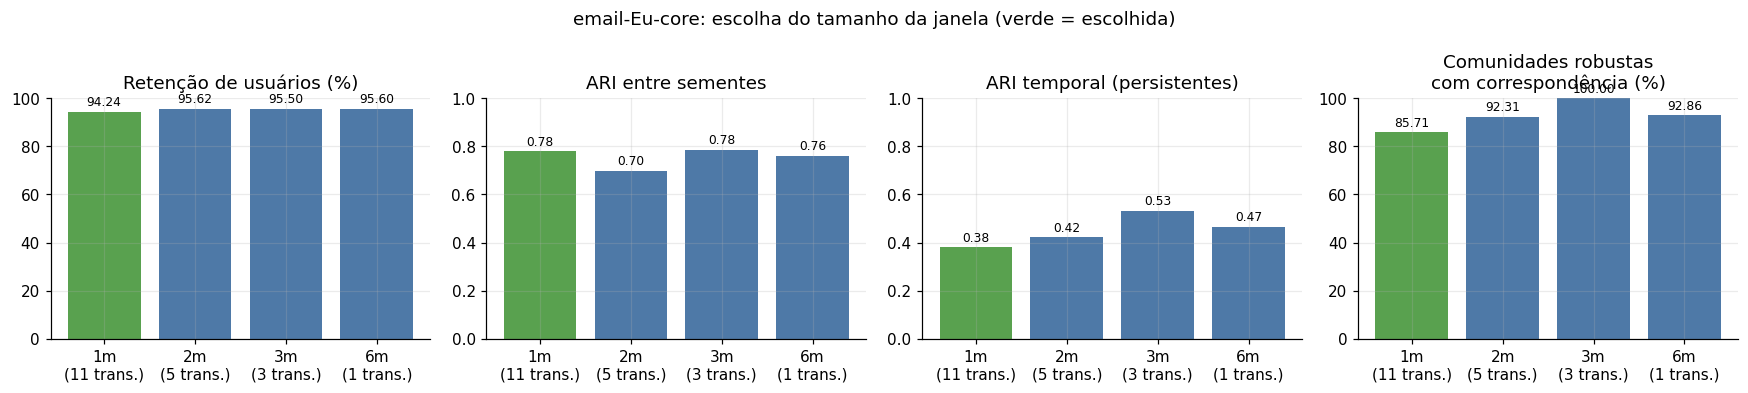

In [13]:
candidatas = comparacion_ventanas.loc[comparacion_ventanas.transiciones.ge(MIN_TRANSICIONES)]
if len(candidatas):
    sugerida = int(candidatas.sort_values(["ari_temporal_mediano", "duracion_meses"], ascending=[False, True]).iloc[0].duracion_meses)
else:
    sugerida = int(comparacion_ventanas.sort_values("transiciones", ascending=False).iloc[0].duracion_meses)
DURACION = VENTANA_MESES if VENTANA_MESES is not None else sugerida
print(f"Duración sugerida por la regla: {sugerida} mes(es). Duración usada: {DURACION} mes(es).")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
etiquetas_x = [f"{m}m\n({t} trans.)" for m, t in zip(comparacion_ventanas.duracion_meses, comparacion_ventanas.transiciones)]
for ax, (col, titulo, lim) in zip(axes, [
        ("retencion_mediana_pct", "Retenção de usuários (%)", (0, 100)),
        ("ari_semillas_mediano", "ARI entre sementes", (0, 1)),
        ("ari_temporal_mediano", "ARI temporal (persistentes)", (0, 1)),
        ("pct_robustas_con_correspondencia", "Comunidades robustas\ncom correspondência (%)", (0, 100))]):
    cores = [VERDE if m == DURACION else AZUL for m in comparacion_ventanas.duracion_meses]
    barras = ax.bar(etiquetas_x, comparacion_ventanas[col], color=cores)
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8)
    ax.set(title=titulo, ylim=lim)
fig.suptitle(f"{NOMBRE_RED}: escolha do tamanho da janela (verde = escolhida)")
plt.tight_layout(); guardar_figura(fig, "fig03_tradeoff_ventanas"); plt.show()

## 6–9. Procesamiento de cada ventana

En cada ventana:

1. Grafo dirigido ponderado (para la importancia) y no dirigido ponderado (para las comunidades).
2. Louvain con `SEMILLAS`, partición medoide y comunidades robustas.
3. **Importancia global, siempre sobre el grafo dirigido completo de la ventana** (todas las componentes, no dentro de una comunidad):
   - **PageRank ponderado normalizado** `pr_norm = PR·N` (media 1, comparable entre ventanas de distinto tamaño) y `log_pr = log10(pr_norm)`.
   - Grado de entrada y de salida.
   - Betweenness aproximada (fuentes muestreadas, sin pesos).
   - **Coeficiente de participación** (Guimerà & Amaral, 2005): 0 si todos los vecinos de un nodo están en su comunidad, cercano a 1 si están repartidos en muchas.
4. **Influenciadores:** el `FRACCION_INFLUENCIADORES` superior de PageRank global (mínimo `MINIMO_INFLUENCIADORES` usuarios).

In [14]:
def coeficiente_participacion(no_dirigidas, asignacion):
    comunidad = asignacion.set_index("usuario").comunidad
    pares = pd.concat([no_dirigidas[["u", "v"]].rename(columns={"u": "n", "v": "vecino"}),
                       no_dirigidas[["v", "u"]].rename(columns={"v": "n", "u": "vecino"})])
    pares["c"] = pares.vecino.map(comunidad)
    k_ic = pares.groupby(["n", "c"]).size()
    k_i = k_ic.groupby(level=0).sum()
    return 1 - (k_ic.div(k_i, level=0) ** 2).groupby(level=0).sum()


def importancia_global(Gd, no_dirigidas, asignacion, betweenness=True):
    N = Gd.number_of_nodes()
    pr = nx.pagerank(Gd, alpha=0.85, weight="weight", max_iter=1000, tol=1e-10)
    tabla = pd.DataFrame({"usuario": list(Gd.nodes())})
    tabla["grado_entrada"] = tabla.usuario.map(dict(Gd.in_degree()))
    tabla["grado_salida"] = tabla.usuario.map(dict(Gd.out_degree()))
    vecinos = pd.concat([no_dirigidas.u, no_dirigidas.v]).value_counts()
    tabla["grado"] = tabla.usuario.map(vecinos)
    tabla["pagerank"] = tabla.usuario.map(pr)
    tabla["pr_norm"] = tabla.pagerank * N
    tabla["log_pr"] = np.log10(tabla.pr_norm)
    tabla["rango_pr"] = tabla.pagerank.rank(ascending=False, method="first").astype(int)
    if betweenness:
        bc = nx.betweenness_centrality(Gd, k=min(MUESTRA_BETWEENNESS, N), normalized=True, weight=None, seed=SEMILLA_GENERAL)
        tabla["betweenness"] = tabla.usuario.map(bc)
        tabla["pct_betweenness"] = tabla.betweenness.rank(pct=True)
    else:
        tabla["betweenness"] = np.nan; tabla["pct_betweenness"] = np.nan
    tabla = tabla.merge(asignacion, on="usuario", how="left", validate="one_to_one")
    tabla["participacion"] = tabla.usuario.map(coeficiente_participacion(no_dirigidas, asignacion))
    return tabla


def es_influenciador(tabla, fraccion=None):
    fraccion = FRACCION_INFLUENCIADORES if fraccion is None else fraccion
    k = max(MINIMO_INFLUENCIADORES, math.ceil(fraccion * len(tabla)))
    return tabla.rango_pr.le(k)


def procesar_ventanas(datos, ventanas, semillas, betweenness=True, guardar_graphml=False, mensajes=True):
    resultados = []
    for i, (a, b) in enumerate(ventanas):
        ev = eventos_en(datos, a, b)
        Gd, Gu, nd = construir_grafos(ev)
        nodos, etiquetas, f_mod = particiones_louvain(Gu, nd, semillas)
        asig, com, ari = resumir_particiones(nodos, etiquetas)
        imp = importancia_global(Gd, nd, asig, betweenness)
        info = {"ventana": i, "inicio": a, "fin_exclusivo": b, **resumen_basico(Gd, Gu, ev),
                "comunidades": len(com), "comunidades_robustas": int(com.robusta.sum()),
                "pct_usuarios_en_robustas": 100 * com.loc[com.robusta, "tamano"].sum() / len(asig),
                "modularidad": f_mod(asig.comunidad.to_numpy()),
                "ari_semillas_mediano": np.median(ari) if ari else np.nan}
        resultados.append({"info": info, "asig": asig, "com": com, "imp": imp, "nd": nd})
        if guardar_graphml:
            atributos = imp.set_index("usuario")
            nx.set_node_attributes(Gd, atributos.comunidad.astype(int).to_dict(), "comunidad")
            nx.set_node_attributes(Gd, atributos.pagerank.astype(float).to_dict(), "pagerank")
            nx.write_graphml(Gd, GRAPHML / f"{PREFIJO}_ventana_{a:%Y-%m-%d}.graphml.gz")
        if mensajes:
            print(f"Ventana {i + 1}/{len(ventanas)} ({a:%Y-%m}): {info['usuarios']:,} usuarios, "
                  f"{info['comunidades_robustas']} comunidades robustas, Q = {info['modularidad']:.3f}")
    return resultados

VENTANAS = ventanas_fijas(INICIO, FIN, DURACION)

# Verificación del backend: la modularidad calculada por igraph debe coincidir con la de NetworkX.
_, _Gu, _nd = construir_grafos(eventos_en(datos_limpios, *VENTANAS[0]))
_nodos, _et, _fmod = particiones_louvain(_Gu, _nd, SEMILLAS[:1])
_grupos = pd.Series(_nodos).groupby(_et[0]).apply(set).tolist()
_q_nx = nx.community.modularity(_Gu, _grupos, weight="weight", resolution=RESOLUCION)
print(f"Verificación de modularidad ({BACKEND}): {_fmod(_et[0]):.6f} vs NetworkX {_q_nx:.6f}")
assert abs(_fmod(_et[0]) - _q_nx) < 1e-6, "La modularidad no coincide: revisar el backend."

inicio_etapa = time.perf_counter()
resultados = procesar_ventanas(datos_limpios, VENTANAS, SEMILLAS, CALCULAR_BETWEENNESS, GUARDAR_GRAPHML_VENTANAS)
tiempos["ventanas"] = time.perf_counter() - inicio_etapa
resumen_ventanas = pd.DataFrame([r["info"] for r in resultados])
display(resumen_ventanas.round(3))

Verificación de modularidad (igraph): 0.685055 vs NetworkX 0.685055
Ventana 1/12 (1970-01): 694 usuarios, 11 comunidades robustas, Q = 0.686
Ventana 2/12 (1970-02): 692 usuarios, 13 comunidades robustas, Q = 0.707
Ventana 3/12 (1970-03): 677 usuarios, 14 comunidades robustas, Q = 0.684
Ventana 4/12 (1970-04): 691 usuarios, 13 comunidades robustas, Q = 0.709
Ventana 5/12 (1970-05): 697 usuarios, 12 comunidades robustas, Q = 0.715
Ventana 6/12 (1970-06): 700 usuarios, 13 comunidades robustas, Q = 0.699
Ventana 7/12 (1970-07): 713 usuarios, 14 comunidades robustas, Q = 0.694
Ventana 8/12 (1970-08): 721 usuarios, 15 comunidades robustas, Q = 0.691
Ventana 9/12 (1970-09): 670 usuarios, 13 comunidades robustas, Q = 0.705
Ventana 10/12 (1970-10): 651 usuarios, 15 comunidades robustas, Q = 0.727
Ventana 11/12 (1970-11): 682 usuarios, 15 comunidades robustas, Q = 0.711
Ventana 12/12 (1970-12): 709 usuarios, 10 comunidades robustas, Q = 0.674


,ventana,inicio,fin_exclusivo,interacciones,usuarios,aristas_dirigidas,aristas_no_dirigidas,grado_medio_no_dirigido,componentes,pct_mayor_componente,comunidades,comunidades_robustas,pct_usuarios_en_robustas,modularidad,ari_semillas_mediano
0,0,1970-01-01 00:00:00+00:00,1970-02-01 00:00:00+00:00,17865,694,4770,3329,9.594,5,98.271,18,11,89.337,0.686,0.736
1,1,1970-02-01 00:00:00+00:00,1970-03-01 00:00:00+00:00,16255,692,4832,3453,9.98,2,99.711,14,13,99.711,0.707,0.861
2,2,1970-03-01 00:00:00+00:00,1970-04-01 00:00:00+00:00,12134,677,4230,3054,9.022,2,99.114,17,14,98.523,0.684,0.773
3,3,1970-04-01 00:00:00+00:00,1970-05-01 00:00:00+00:00,17762,691,4817,3390,9.812,2,99.711,16,13,98.263,0.709,0.806
4,4,1970-05-01 00:00:00+00:00,1970-06-01 00:00:00+00:00,19922,697,5010,3548,10.181,1,100,13,12,99.713,0.715,0.706
5,5,1970-06-01 00:00:00+00:00,1970-07-01 00:00:00+00:00,19080,700,4988,3535,10.1,2,99.571,14,13,99.571,0.699,0.67
6,6,1970-07-01 00:00:00+00:00,1970-08-01 00:00:00+00:00,19002,713,5225,3700,10.379,3,99.158,17,14,98.878,0.694,0.845
7,7,1970-08-01 00:00:00+00:00,1970-09-01 00:00:00+00:00,28230,721,5931,4210,11.678,1,100,16,15,99.584,0.691,0.706
8,8,1970-09-01 00:00:00+00:00,1970-10-01 00:00:00+00:00,15068,670,4578,3217,9.603,1,100,14,13,98.806,0.705,0.794
9,9,1970-10-01 00:00:00+00:00,1970-11-01 00:00:00+00:00,10736,651,3492,2535,7.788,3,99.232,18,15,98.157,0.727,0.776


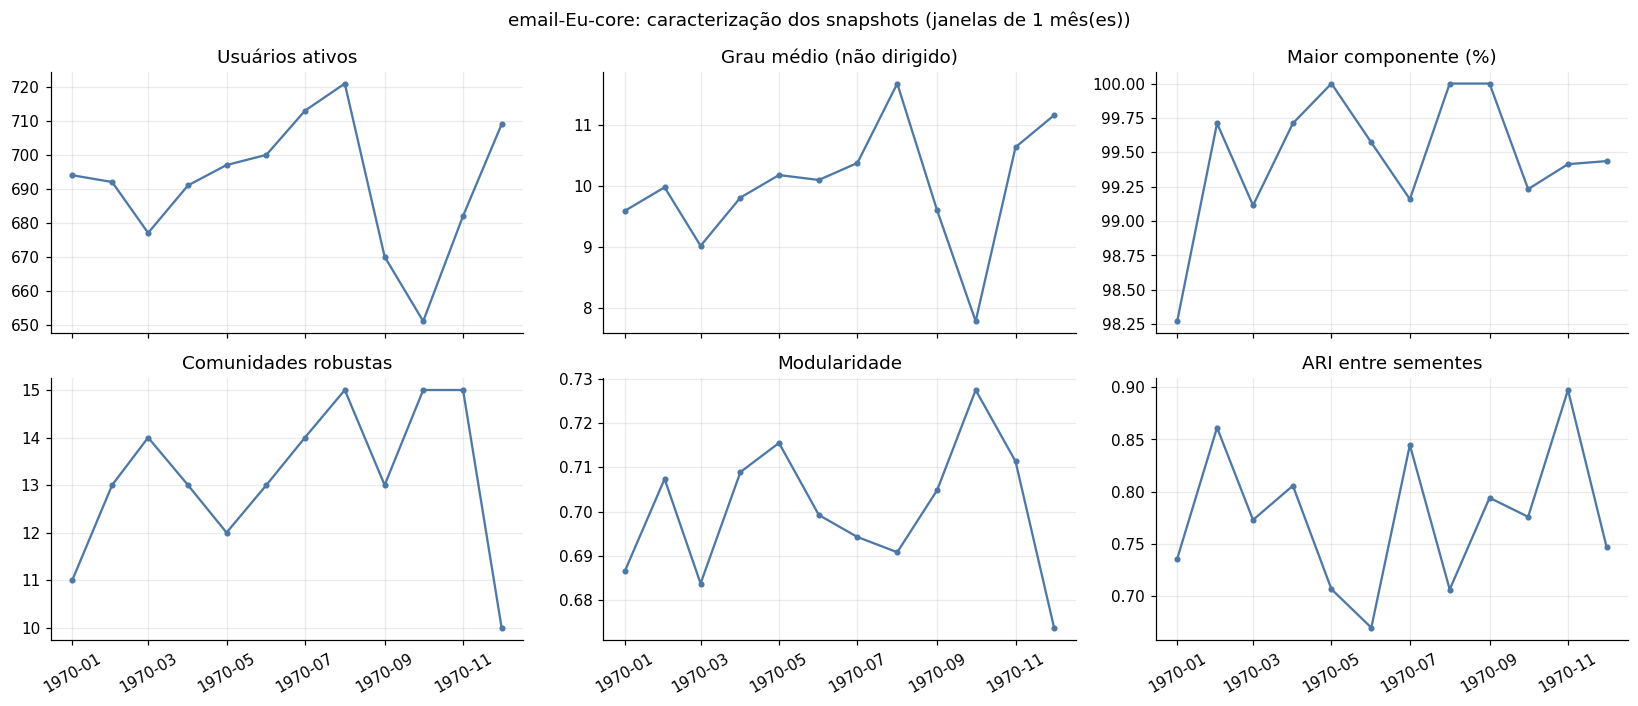

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
for ax, (col, titulo) in zip(axes.flat, [
        ("usuarios", "Usuários ativos"), ("grado_medio_no_dirigido", "Grau médio (não dirigido)"),
        ("pct_mayor_componente", "Maior componente (%)"), ("comunidades_robustas", "Comunidades robustas"),
        ("modularidad", "Modularidade"), ("ari_semillas_mediano", "ARI entre sementes")]):
    ax.plot(resumen_ventanas.inicio, resumen_ventanas[col], "o-", ms=3, color=AZUL)
    ax.set_title(titulo); ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{NOMBRE_RED}: caracterização dos snapshots (janelas de {DURACION} mês(es))")
plt.tight_layout(); guardar_figura(fig, "fig04_snapshots"); plt.show()

## 10. Evolución de las comunidades: eventos y linajes

Relacionamos las comunidades robustas de ventanas consecutivas mediante sus usuarios **persistentes**. Hay un enlace cuando comparten al menos `MINIMO_COMPARTIDOS` usuarios y la cobertura (sobre persistentes) supera `UMBRAL_COBERTURA` en alguno de los dos lados. Con un umbral ≥ 0,5, cada comunidad tiene como máximo un "heredero principal" por lado, así que las divisiones y fusiones quedan bien definidas.

Los **linajes** encadenan comunidades a lo largo del tiempo:

- En una división, el sucesor con más usuarios compartidos hereda el linaje.
- En una fusión, el linaje del predecesor con más compartidos continúa y los demás terminan.

Con los linajes medimos el tiempo de vida (curva de supervivencia de Kaplan–Meier).

,eventos
tipo,
Estable,31
Crecimiento,42
Contracción,33
División,9
Fusión,9
Reorganización,0
Aparición,14
Desaparición,14


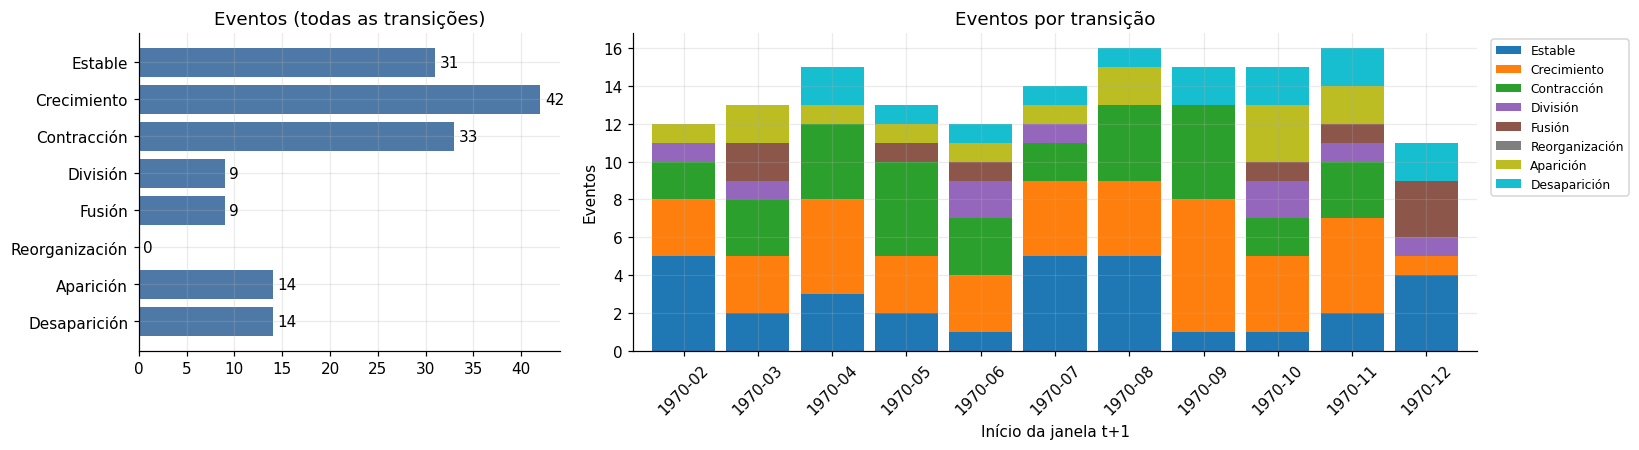

In [16]:
def analizar_transicion(A, B, umbral):
    pares, comunes, pers_a = correspondencias(A["asig"], B["asig"], A["com"], B["com"])
    enlaces, eventos, evento_de_a = identificar_eventos(pares, A["com"], B["com"], pers_a, umbral)
    return {"pares": pares, "comunes": comunes, "pers_a": pers_a, "enlaces": enlaces,
            "eventos": eventos, "evento_de_a": evento_de_a}

transiciones = [analizar_transicion(resultados[t], resultados[t + 1], UMBRAL_COBERTURA) for t in range(len(resultados) - 1)]

ORDEN_EVENTOS = ["Estable", "Crecimiento", "Contracción", "División", "Fusión", "Reorganización", "Aparición", "Desaparición"]
eventos_comunidades = pd.concat([tr["eventos"].assign(transicion=t, inicio_b=resultados[t + 1]["info"]["inicio"])
                                 for t, tr in enumerate(transiciones)], ignore_index=True)
conteo_eventos = eventos_comunidades.tipo.value_counts().reindex(ORDEN_EVENTOS, fill_value=0)
display(conteo_eventos.to_frame("eventos"))
sin_robustas = [r["info"]["inicio"].strftime("%Y-%m") for r in resultados if r["info"]["comunidades_robustas"] == 0]
if sin_robustas:
    print(f"Aviso: {len(sin_robustas)} ventana(s) sin comunidades robustas: {sin_robustas}. "
          "Revisen la actividad de esas ventanas o el umbral de robustez.")

por_transicion = (eventos_comunidades.groupby(["inicio_b", "tipo"]).size().unstack(fill_value=0)
                  .reindex(columns=ORDEN_EVENTOS, fill_value=0))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 2]})
barras = axes[0].barh(conteo_eventos.index, conteo_eventos.values, color=AZUL)
axes[0].bar_label(barras, padding=3); axes[0].invert_yaxis(); axes[0].set_title("Eventos (todas as transições)")
if len(por_transicion):
    por_transicion.set_axis([f"{d:%Y-%m}" for d in por_transicion.index], axis=0).plot(
        ax=axes[1], kind="bar", stacked=True, width=0.85, colormap="tab10")
axes[1].set(title="Eventos por transição", xlabel="Início da janela t+1", ylabel="Eventos")
axes[1].tick_params(axis="x", rotation=45)
if len(por_transicion):
    axes[1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); guardar_figura(fig, "fig05_eventos"); plt.show()

## 10b. Validación con comunidades conocidas (solo email-Eu-core)

En email-Eu-core, la versión estática de SNAP trae el **departamento** de cada persona (42 departamentos), una "verdad de referencia" para las comunidades. SNAP advierte que los IDs de la versión temporal no coinciden con los de la estática. La red temporal corresponde a la componente gigante (986 nodos) de la estática (1.005 nodos), así que probamos dos correspondencias de IDs:

1. **Identidad** (mismo ID).
2. **Reindexado ordenado:** los nodos de la componente gigante, en orden creciente, renumerados 0, 1, 2…

Aceptamos una correspondencia solo si **≥ 90 %** de los pares que interactúan en la red temporal existen también en la red estática. Si ninguna pasa, la validación se omite y se informa.

Con etiquetas válidas medimos, en cada ventana:

- **NMI y ARI** entre la partición de Louvain y los departamentos: ¿Louvain recupera estructura real?
- **Modularidad** de la partición por departamentos vs. la de Louvain.
- **% de aristas dentro del mismo departamento.**
- **Continuidad de los departamentos** en la partición: de los pares de usuarios persistentes del mismo departamento que estaban juntos en *t*, qué fracción sigue junta en *t+1*.

In [17]:
from sklearn.metrics import normalized_mutual_info_score
validacion_departamentos, departamento = None, None
if URL_ETIQUETAS and URL_ESTATICA:
    try:
        rutas = []
        for url in (URL_ESTATICA, URL_ETIQUETAS):
            ruta = Path(url.split("/")[-1])
            if not ruta.exists():
                urlretrieve(url, ruta)
            rutas.append(ruta)
        estatica = pd.read_csv(rutas[0], sep=r"\s+", header=None, names=["s", "t"])
        etiquetas = pd.read_csv(rutas[1], sep=r"\s+", header=None, names=["nodo", "departamento"]).set_index("nodo").departamento
        G_est = nx.from_pandas_edgelist(estatica, "s", "t", create_using=nx.DiGraph)
        gigante = sorted(max(nx.weakly_connected_components(G_est), key=len))
        aristas_est = set(zip(estatica.s, estatica.t))
        pares_temp = base_analisis[["source", "target"]].drop_duplicates()
        candidatos = {"identidad": {u: u for u in np.union1d(pares_temp.source, pares_temp.target)},
                      "reindexado ordenado de la componente gigante": dict(enumerate(gigante))}
        cobertura = {}
        for nombre, m in candidatos.items():
            mapeados = [(m.get(a), m.get(b)) for a, b in pares_temp.itertuples(index=False)]
            cobertura[nombre] = np.mean([par in aristas_est for par in mapeados])
        print("Componente gigante estática:", len(gigante), "nodos")
        print("Cobertura de pares temporales en la red estática:", {k: round(v, 3) for k, v in cobertura.items()})
        mejor = max(cobertura, key=cobertura.get)
        if cobertura[mejor] >= 0.90:
            mapa = candidatos[mejor]
            departamento = pd.Series({u: etiquetas.get(v) for u, v in mapa.items()}).dropna().astype(int)
            print(f"Correspondencia aceptada: {mejor}. Usuarios con departamento: {len(departamento)}")
        else:
            print("Ninguna correspondencia alcanza 90 %: se omite la validación con departamentos.")
    except Exception as error:
        print("No se pudo realizar la validación:", error)

if departamento is not None:
    filas = []
    for i, ((a, b), r) in enumerate(zip(VENTANAS, resultados)):
        asig = r["asig"].assign(departamento=lambda x: x.usuario.map(departamento)).dropna(subset=["departamento"])
        _, Gu, nd = construir_grafos(eventos_en(datos_limpios, a, b))
        dep_nodo = {u: departamento.get(u, -1 - k) for k, u in enumerate(Gu.nodes())}
        grupos_dep = pd.Series(list(dep_nodo.keys())).groupby(list(dep_nodo.values())).apply(set).tolist()
        mismo = nd.u.map(departamento).eq(nd.v.map(departamento))
        filas.append({"inicio": a, "usuarios": len(asig),
                      "departamentos_presentes": asig.departamento.nunique(),
                      "comunidades_louvain": asig.comunidad.nunique(),
                      "NMI_louvain_departamentos": normalized_mutual_info_score(asig.departamento, asig.comunidad),
                      "ARI_louvain_departamentos": adjusted_rand_score(asig.departamento, asig.comunidad),
                      "modularidad_louvain": r["info"]["modularidad"],
                      "modularidad_departamentos": nx.community.modularity(Gu, grupos_dep, weight="weight", resolution=RESOLUCION),
                      "pct_aristas_mismo_departamento": 100 * mismo.mean()})
    validacion_departamentos = pd.DataFrame(filas)
    # continuidad: pares del mismo departamento juntos en t que siguen juntos en t+1
    cont = []
    for t, tr in enumerate(transiciones):
        c = tr["comunes"].assign(dep=lambda x: x.usuario.map(departamento)).dropna(subset=["dep"])
        juntos_a = c.groupby(["dep", "comunidad_a"]).size()
        juntos_ab = c.groupby(["dep", "comunidad_a", "comunidad_b"]).size()
        pares_a = (juntos_a * (juntos_a - 1) / 2).sum(); pares_ab = (juntos_ab * (juntos_ab - 1) / 2).sum()
        cont.append(pares_ab / pares_a if pares_a else np.nan)
    validacion_departamentos["continuidad_pares_departamento"] = [np.nan] + cont
    display(validacion_departamentos.round(3))
    validacion_departamentos.to_csv(CARPETA / "validacion_departamentos.csv", index=False)

    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    axes[0].plot(validacion_departamentos.inicio, validacion_departamentos.NMI_louvain_departamentos, "o-", color=AZUL, label="NMI")
    axes[0].plot(validacion_departamentos.inicio, validacion_departamentos.ARI_louvain_departamentos, "s-", color=LILA, label="ARI")
    axes[0].set(title="Louvain × departamentos", ylim=(0, 1)); axes[0].legend()
    axes[1].plot(validacion_departamentos.inicio, validacion_departamentos.modularidad_louvain, "o-", color=AZUL, label="Louvain")
    axes[1].plot(validacion_departamentos.inicio, validacion_departamentos.modularidad_departamentos, "s-", color=NARANJA, label="Departamentos")
    axes[1].set(title="Modularidade"); axes[1].legend()
    axes[2].plot(validacion_departamentos.inicio, validacion_departamentos.continuidad_pares_departamento, "o-", color=VERDE)
    axes[2].set(title="Pares do mesmo departamento que\nseguem juntos na janela seguinte", ylim=(0, 1))
    for ax in axes:
        ax.tick_params(axis="x", rotation=30)
    fig.suptitle(f"{NOMBRE_RED}: validação com os departamentos")
    plt.tight_layout(); guardar_figura(fig, "fig04b_validacion_departamentos"); plt.show()

Componente gigante estática: 986 nodos
Cobertura de pares temporales en la red estática: {'identidad': np.float64(0.024), 'reindexado ordenado de la componente gigante': np.float64(0.025)}
Ninguna correspondencia alcanza 90 %: se omite la validación con departamentos.


Linajes: 34 | vida mediana: 3 ventana(s) | activos al final: 10


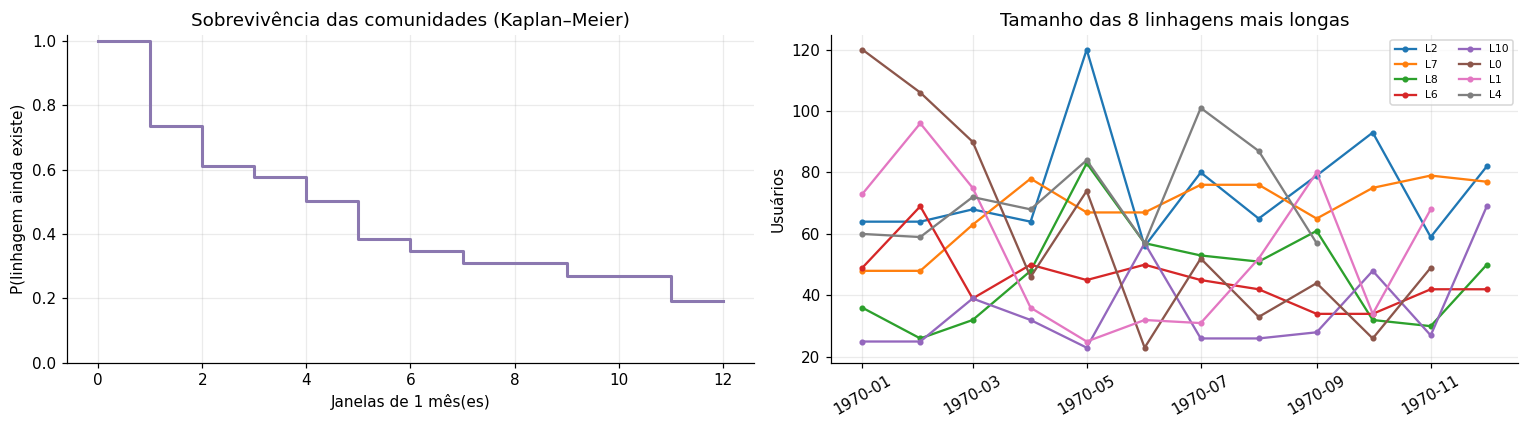

In [18]:
if sum(r["info"]["comunidades_robustas"] for r in resultados) == 0:
    raise RuntimeError("Ninguna ventana tiene comunidades robustas: el análisis temporal no es posible con esta "
                       "configuración. Revisen MINIMO_COMUNIDAD, UMBRAL_ROBUSTEZ o la duración de la ventana.")

def construir_linajes(resultados, transiciones):
    linaje, proximo = {}, 0
    for c in resultados[0]["com"].comunidad[resultados[0]["com"].robusta]:
        linaje[(0, int(c))] = proximo; proximo += 1
    for t, tr in enumerate(transiciones):
        usados_a, usados_b = set(), set()
        for r in tr["enlaces"].sort_values("compartidos", ascending=False).itertuples():
            a, b = int(r.comunidad_a), int(r.comunidad_b)
            if a not in usados_a and b not in usados_b and (t, a) in linaje:
                linaje[(t + 1, b)] = linaje[(t, a)]; usados_a.add(a); usados_b.add(b)
        for c in resultados[t + 1]["com"].comunidad[resultados[t + 1]["com"].robusta]:
            if (t + 1, int(c)) not in linaje:
                linaje[(t + 1, int(c))] = proximo; proximo += 1
    filas = []
    for (t, c), l in linaje.items():
        imp = resultados[t]["imp"]
        miembros = imp.comunidad.eq(c)
        filas.append({"linaje": l, "ventana": t, "inicio": resultados[t]["info"]["inicio"], "comunidad": c,
                      "tamano": int(miembros.sum()),
                      "influenciadores": int((miembros & es_influenciador(imp)).sum())})
    return pd.DataFrame(filas).sort_values(["linaje", "ventana"]).reset_index(drop=True)

linajes = construir_linajes(resultados, transiciones)
ultima = len(resultados) - 1
vida = linajes.groupby("linaje").agg(nacimiento=("ventana", "min"), fin=("ventana", "max"),
                                     duracion=("ventana", "size"), tamano_medio=("tamano", "mean"),
                                     influenciadores_max=("influenciadores", "max"))
vida["termino"] = vida.fin.lt(ultima)   # False = sigue viva al final (censurada)

def kaplan_meier(duraciones, evento):
    tiempos_km = np.sort(np.unique(duraciones))
    s, curva = 1.0, [(0, 1.0)]
    for d in tiempos_km:
        en_riesgo = (duraciones >= d).sum(); murieron = ((duraciones == d) & evento).sum()
        if en_riesgo:
            s *= 1 - murieron / en_riesgo
        curva.append((d, s))
    return pd.DataFrame(curva, columns=["ventanas", "supervivencia"])

km = kaplan_meier(vida.duracion.to_numpy(), vida.termino.to_numpy())
print(f"Linajes: {len(vida):,} | vida mediana: {vida.duracion.median():.0f} ventana(s) | "
      f"activos al final: {(~vida.termino).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].step(km.ventanas, km.supervivencia, where="post", color=LILA, lw=2)
axes[0].set(title="Sobrevivência das comunidades (Kaplan–Meier)", xlabel=f"Janelas de {DURACION} mês(es)",
            ylabel="P(linhagem ainda existe)", ylim=(0, 1.02))
mayores = vida.sort_values(["duracion", "tamano_medio"], ascending=False).head(8).index
for l in mayores:
    s = linajes.loc[linajes.linaje.eq(l)]
    axes[1].plot(s.inicio, s.tamano, "o-", ms=3, label=f"L{l}")
axes[1].set(title="Tamanho das 8 linhagens mais longas", ylabel="Usuários"); axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); guardar_figura(fig, "fig06_linajes"); plt.show()

## 11. Influenciadores: estabilidad y posición respecto a las comunidades

Antes de relacionar ambos fenómenos, describimos los influenciadores:

- ¿Cuántos siguen en el top de una ventana a la siguiente?
- ¿El orden global de PageRank se mantiene entre los usuarios persistentes?
- ¿Los influenciadores están **dentro** de una comunidad o **entre** comunidades (coeficiente de participación)?

La última pregunta ayuda a interpretar H1: si los influenciadores son transversales, su importancia puede no depender de una comunidad específica.

,transicion,inicio_b,jaccard_top,pct_top_sigue_top,pct_top_sigue_activo,spearman_logpr_persistentes
0,0,1970-02-01 00:00:00+00:00,0.25,40,100,0.788
1,1,1970-03-01 00:00:00+00:00,0.25,40,100,0.765
2,2,1970-04-01 00:00:00+00:00,0.25,40,100,0.756
3,3,1970-05-01 00:00:00+00:00,0.429,60,100,0.815
4,4,1970-06-01 00:00:00+00:00,0.25,40,100,0.82
5,5,1970-07-01 00:00:00+00:00,0.429,60,100,0.823
6,6,1970-08-01 00:00:00+00:00,0.176,30,100,0.82
7,7,1970-09-01 00:00:00+00:00,0.176,30,100,0.795
8,8,1970-10-01 00:00:00+00:00,0.333,50,100,0.727
9,9,1970-11-01 00:00:00+00:00,0.25,40,100,0.747


,inicio,participacion_influenciadores,participacion_resto,comunidades_con_influenciadores,influenciadores
0,1970-01-01 00:00:00+00:00,0.701,0.444,5,10
1,1970-02-01 00:00:00+00:00,0.69,0.426,6,10
2,1970-03-01 00:00:00+00:00,0.71,0.406,6,10
3,1970-04-01 00:00:00+00:00,0.557,0.444,7,10
4,1970-05-01 00:00:00+00:00,0.629,0.379,5,10
5,1970-06-01 00:00:00+00:00,0.713,0.449,6,10
6,1970-07-01 00:00:00+00:00,0.699,0.444,6,10
7,1970-08-01 00:00:00+00:00,0.786,0.5,5,10
8,1970-09-01 00:00:00+00:00,0.587,0.444,6,10
9,1970-10-01 00:00:00+00:00,0.604,0.444,7,10


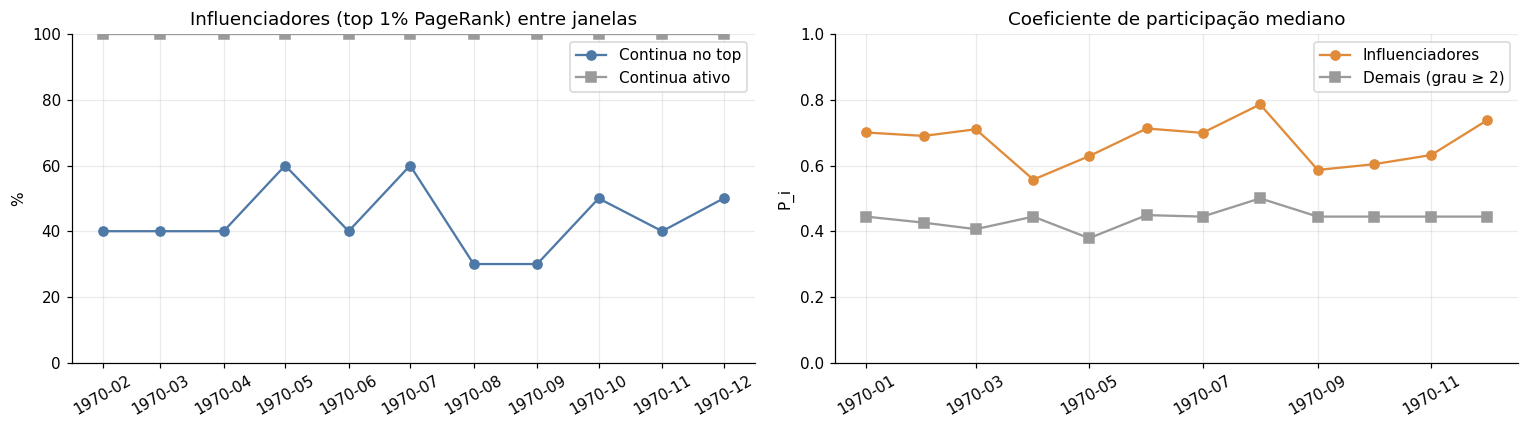

In [19]:
filas_infl = []
for t, tr in enumerate(transiciones):
    ia, ib = resultados[t]["imp"], resultados[t + 1]["imp"]
    top_a = set(ia.usuario[es_influenciador(ia)]); top_b = set(ib.usuario[es_influenciador(ib)])
    persistentes = ia[["usuario", "log_pr"]].merge(ib[["usuario", "log_pr"]], on="usuario", suffixes=("_a", "_b"))
    filas_infl.append({
        "transicion": t, "inicio_b": resultados[t + 1]["info"]["inicio"],
        "jaccard_top": len(top_a & top_b) / len(top_a | top_b),
        "pct_top_sigue_top": 100 * len(top_a & top_b) / len(top_a),
        "pct_top_sigue_activo": 100 * len(top_a & set(ib.usuario)) / len(top_a),
        "spearman_logpr_persistentes": persistentes.log_pr_a.corr(persistentes.log_pr_b, method="spearman"),
    })
estabilidad_influenciadores = pd.DataFrame(filas_infl)

filas_part = []
for r in resultados:
    imp = r["imp"]; top = es_influenciador(imp)
    filas_part.append({"inicio": r["info"]["inicio"],
                       "participacion_influenciadores": imp.participacion[top].median(),
                       "participacion_resto": imp.participacion[~top & imp.grado.ge(2)].median(),
                       "comunidades_con_influenciadores": imp.comunidad[top].nunique(),
                       "influenciadores": int(top.sum())})
participacion = pd.DataFrame(filas_part)
display(estabilidad_influenciadores.round(3)); display(participacion.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(estabilidad_influenciadores.inicio_b, estabilidad_influenciadores.pct_top_sigue_top, "o-", color=AZUL, label="Continua no top")
axes[0].plot(estabilidad_influenciadores.inicio_b, estabilidad_influenciadores.pct_top_sigue_activo, "s-", color=GRIS, label="Continua ativo")
axes[0].set(title=f"Influenciadores (top {100 * FRACCION_INFLUENCIADORES:g}% PageRank) entre janelas", ylabel="%", ylim=(0, 100))
axes[0].legend(); axes[0].tick_params(axis="x", rotation=30)
axes[1].plot(participacion.inicio, participacion.participacion_influenciadores, "o-", color=NARANJA, label="Influenciadores")
axes[1].plot(participacion.inicio, participacion.participacion_resto, "s-", color=GRIS, label="Demais (grau ≥ 2)")
axes[1].set(title="Coeficiente de participação mediano", ylabel="P_i", ylim=(0, 1)); axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); guardar_figura(fig, "fig07_influenciadores"); plt.show()

## 12. H2 — Nivel usuario: conservación del entorno comunitario vs. cambio de posición global

Para cada usuario persistente *u* cuya comunidad en *t* es robusta:

- **Conservación del entorno** `s_u`: de sus antiguos compañeros de comunidad que siguen activos en *t+1*, la fracción que sigue en su misma comunidad. Requiere al menos 2 compañeros persistentes.
- **Cambio de posición global** `|Δ log10 PR_norm|`.
- **Control 1:** log del grado en *t*. Los usuarios con muchos vecinos tienden a ser más estables en ambas medidas.
- **Control 2 (más estricto):** Jaccard entre los **vecinos directos** del usuario en *t* y en *t+1*. Si alguien conversa con las mismas personas, conserva tanto su comunidad como su PageRank, y la asociación sería trivial. Si sobrevive a este control, el **contexto comunitario** (más allá de los vecinos directos) está asociado a la importancia global.

**Nulo:** se permutan las comunidades de *t+1* entre los usuarios persistentes, conservando los tamaños, y se recalcula el ρ parcial (`N_PERMUTACIONES` veces). Si la estructura comunitaria no aportara información, el ρ observado caería dentro de esa distribución.

In [20]:
def rangos(x):
    return pd.Series(x).rank().to_numpy()


def spearman_parcial(x, y, covariables=()):
    df = pd.DataFrame({"x": np.asarray(x, float), "y": np.asarray(y, float),
                       **{f"z{i}": np.asarray(z, float) for i, z in enumerate(covariables)}}).dropna()
    if len(df) < 10 or df.x.nunique() < 2 or df.y.nunique() < 2:
        return np.nan
    r = df.rank()
    Z = np.column_stack([np.ones(len(r))] + [r[f"z{i}"] for i in range(len(covariables))])
    rx = r.x - Z @ np.linalg.lstsq(Z, r.x, rcond=None)[0]
    ry = r.y - Z @ np.linalg.lstsq(Z, r.y, rcond=None)[0]
    if rx.std() == 0 or ry.std() == 0:
        return np.nan
    return float(np.corrcoef(rx, ry)[0, 1])


def conservacion_entorno(comunidad_a, comunidad_b):
    df = pd.DataFrame({"a": comunidad_a, "b": comunidad_b})
    n_par = df.groupby(["a", "b"])["a"].transform("size")
    n_a = df.groupby("a")["a"].transform("size")
    return np.where(n_a >= 3, (n_par - 1) / (n_a - 1), np.nan)


def pares_vecinos(nd):
    return pd.concat([nd[["u", "v"]].set_axis(["n", "w"], axis=1), nd[["v", "u"]].set_axis(["n", "w"], axis=1)])


def tabla_usuarios(t, tr):
    A, B = resultados[t], resultados[t + 1]
    columnas = ["usuario", "comunidad", "log_pr", "grado", "pct_betweenness"]
    u = A["imp"][columnas].merge(B["imp"][columnas], on="usuario", suffixes=("_a", "_b"))
    u["influenciador_a"] = u.usuario.isin(A["imp"].usuario[es_influenciador(A["imp"])])
    u["s"] = conservacion_entorno(u.comunidad_a.to_numpy(), u.comunidad_b.to_numpy())
    u["delta_log_pr"] = u.log_pr_b - u.log_pr_a
    u["abs_delta_log_pr"] = u.delta_log_pr.abs()
    u["delta_pct_betweenness"] = u.pct_betweenness_b - u.pct_betweenness_a
    u["log_grado_a"] = np.log10(u.grado_a)
    # Jaccard de vecinos directos entre t y t+1
    pa, pb = pares_vecinos(A["nd"]), pares_vecinos(B["nd"])
    comunes = pa.merge(pb, on=["n", "w"]).groupby("n").size()
    c = u.usuario.map(comunes).fillna(0).to_numpy()
    u["jaccard_vecinos"] = c / (u.grado_a.to_numpy() + u.grado_b.to_numpy() - c)
    u["robusta_a"] = u.comunidad_a.isin(A["com"].comunidad[A["com"].robusta])
    u["tipo_evento"] = u.comunidad_a.map(lambda c: tr["evento_de_a"].get(c, (None, "No robusta"))[1])
    u["transicion"] = t
    return u


def _resumir_nulo(obs, nulos):
    nulos = np.array([v for v in nulos if not np.isnan(v)])
    if not len(nulos) or np.isnan(obs):
        return np.nan, np.nan, np.nan, np.nan
    p = (1 + np.sum(np.abs(nulos - nulos.mean()) >= abs(obs - nulos.mean()))) / (len(nulos) + 1)
    return nulos.mean(), np.percentile(nulos, 2.5), np.percentile(nulos, 97.5), p


def h2_transicion(u, n_perm, rng):
    """ρ parcial entre s_u y |Δ log PR| con dos conjuntos de controles, cada uno con su nulo por permutación."""
    validos = (u.robusta_a & u.s.notna()).to_numpy()
    y = u.abs_delta_log_pr.to_numpy(); g = u.log_grado_a.to_numpy(); jv = u.jaccard_vecinos.to_numpy()
    s_obs = u.s.to_numpy()
    obs_g = spearman_parcial(s_obs[validos], y[validos], [g[validos]])
    obs_v = spearman_parcial(s_obs[validos], y[validos], [g[validos], jv[validos]])
    nulos_g, nulos_v = [], []
    for _ in range(n_perm):
        s_perm = conservacion_entorno(u.comunidad_a.to_numpy(), rng.permutation(u.comunidad_b.to_numpy()))
        v = validos & ~np.isnan(s_perm)
        nulos_g.append(spearman_parcial(s_perm[v], y[v], [g[v]]))
        nulos_v.append(spearman_parcial(s_perm[v], y[v], [g[v], jv[v]]))
    mg, ig_, sg, pg = _resumir_nulo(obs_g, nulos_g)
    mv, iv, sv, pv = _resumir_nulo(obs_v, nulos_v)
    return {"usuarios": int(validos.sum()),
            "rho_parcial": obs_g, "nulo_media": mg, "nulo_p2_5": ig_, "nulo_p97_5": sg, "p_valor": pg,
            "rho_parcial_vecinos": obs_v, "nulo_v_p2_5": iv, "nulo_v_p97_5": sv, "p_valor_vecinos": pv,
            "mediana_s": np.nanmedian(s_obs[validos]) if validos.any() else np.nan,
            "mediana_jaccard_vecinos": np.nanmedian(jv[validos]) if validos.any() else np.nan,
            "mediana_abs_delta_log_pr": np.median(y[validos]) if validos.any() else np.nan}

inicio_etapa = time.perf_counter()
rng = np.random.default_rng(SEMILLA_GENERAL)
usuarios_transiciones, filas_h2 = [], []
for t, tr in enumerate(transiciones):
    u = tabla_usuarios(t, tr)
    usuarios_transiciones.append(u)
    filas_h2.append({"transicion": t, "inicio_b": resultados[t + 1]["info"]["inicio"], **h2_transicion(u, N_PERMUTACIONES, rng)})
usuarios_todos = pd.concat(usuarios_transiciones, ignore_index=True)
h2 = pd.DataFrame(filas_h2)
h2["fuera_del_nulo"] = (h2.rho_parcial < h2.nulo_p2_5) | (h2.rho_parcial > h2.nulo_p97_5)
h2["fuera_del_nulo_vecinos"] = (h2.rho_parcial_vecinos < h2.nulo_v_p2_5) | (h2.rho_parcial_vecinos > h2.nulo_v_p97_5)
tiempos["h2"] = time.perf_counter() - inicio_etapa
display(h2.round(4))

,transicion,inicio_b,usuarios,rho_parcial,nulo_media,nulo_p2_5,nulo_p97_5,p_valor,rho_parcial_vecinos,nulo_v_p2_5,nulo_v_p97_5,p_valor_vecinos,mediana_s,mediana_jaccard_vecinos,mediana_abs_delta_log_pr,fuera_del_nulo,fuera_del_nulo_vecinos
0,0,1970-02-01 00:00:00+00:00,586,-0.0202,-0.0027,-0.0805,0.0808,0.7114,-0.0084,-0.0826,0.0843,0.9204,0.5965,0.3889,0.1274,False,False
1,1,1970-03-01 00:00:00+00:00,639,-0.038,-0.0012,-0.0766,0.0804,0.4677,-0.0068,-0.0805,0.0773,0.9104,0.5165,0.3571,0.1235,False,False
2,2,1970-04-01 00:00:00+00:00,631,-0.0233,-0.0019,-0.0718,0.072,0.602,0.0107,-0.0752,0.0733,0.7761,0.5,0.3333,0.1343,False,False
3,3,1970-05-01 00:00:00+00:00,642,0.0136,-0.0029,-0.0655,0.0732,0.6866,0.0371,-0.0728,0.0744,0.2786,0.7257,0.3772,0.1183,False,False
4,4,1970-06-01 00:00:00+00:00,653,-0.042,0.0057,-0.0756,0.0833,0.2687,-0.021,-0.0681,0.0829,0.5622,0.4433,0.3889,0.1153,False,False
5,5,1970-07-01 00:00:00+00:00,664,-0.0572,0.0008,-0.0712,0.0912,0.1393,-0.0438,-0.0689,0.0884,0.2488,0.6429,0.4,0.1078,False,False
6,6,1970-08-01 00:00:00+00:00,670,-0.1395,0.0036,-0.0637,0.0874,0.005,-0.1142,-0.0687,0.0828,0.005,0.5849,0.375,0.1233,True,True
7,7,1970-09-01 00:00:00+00:00,643,0.0334,-0.0012,-0.0762,0.0711,0.3532,0.0632,-0.0784,0.0712,0.1095,0.5806,0.3333,0.1342,False,False
8,8,1970-10-01 00:00:00+00:00,597,0.0034,0.0008,-0.0856,0.0856,0.9403,0.044,-0.0836,0.0828,0.3184,0.3636,0.3333,0.1598,False,False
9,9,1970-11-01 00:00:00+00:00,605,-0.1148,0.0036,-0.0725,0.0786,0.0199,-0.0676,-0.0702,0.072,0.0547,0.4634,0.3333,0.1429,True,False


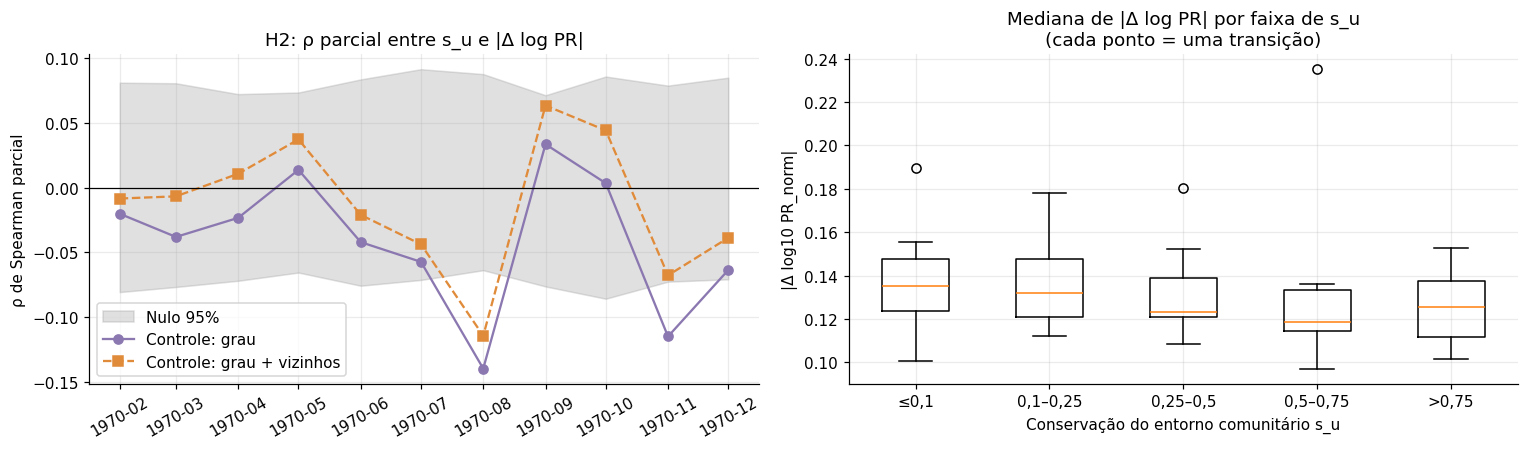

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].fill_between(h2.inicio_b, h2.nulo_p2_5, h2.nulo_p97_5, color=GRIS, alpha=0.3, label="Nulo 95%")
axes[0].plot(h2.inicio_b, h2.rho_parcial, "o-", color=LILA, label="Controle: grau")
axes[0].plot(h2.inicio_b, h2.rho_parcial_vecinos, "s--", color=NARANJA, label="Controle: grau + vizinhos")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(title="H2: ρ parcial entre s_u e |Δ log PR|", ylabel="ρ de Spearman parcial")
axes[0].legend(); axes[0].tick_params(axis="x", rotation=30)

validos = usuarios_todos.loc[usuarios_todos.robusta_a & usuarios_todos.s.notna()].copy()
validos["faixa_s"] = pd.cut(validos.s, [-0.001, 0.1, 0.25, 0.5, 0.75, 1.0],
                            labels=["≤0,1", "0,1–0,25", "0,25–0,5", "0,5–0,75", ">0,75"])
mediana_faixa = validos.groupby(["transicion", "faixa_s"], observed=True).abs_delta_log_pr.median().unstack()
axes[1].boxplot([mediana_faixa[c].dropna() for c in mediana_faixa.columns])
axes[1].set_xticks(range(1, len(mediana_faixa.columns) + 1), list(mediana_faixa.columns))
axes[1].set(title="Mediana de |Δ log PR| por faixa de s_u\n(cada ponto = uma transição)",
            xlabel="Conservação do entorno comunitário s_u", ylabel="|Δ log10 PR_norm|")
plt.tight_layout(); guardar_figura(fig, "fig08_h2_usuarios"); plt.show()

## 13. H1 — Nivel comunidad: ¿las comunidades estables conservan a sus influenciadores?

Unidad de análisis: cada comunidad robusta *C* en *t* con al menos un influenciador y al menos 3 miembros persistentes.

- **Estabilidad** de *C*: mayor Jaccard (sobre persistentes) con alguna comunidad robusta de *t+1*. Es continua y no depende del umbral de eventos.
- **Retención de influenciadores** (Y1): entre los influenciadores de *C* que siguen activos, la fracción que **sigue en el top global**. Así se separa el abandono de la pérdida de importancia.
- **Y2:** mediana de |Δ log PR| de los miembros persistentes de *C*.
- **Controles:** log del tamaño y retención de miembros (fracción que sigue activa).

**Nulo:** se permuta la estabilidad entre comunidades **dentro de cada transición**.

In [22]:
def tabla_comunidades(t, tr, fraccion=None):
    A, B = resultados[t], resultados[t + 1]
    ia, ib = A["imp"], B["imp"]
    top_a = set(ia.usuario[es_influenciador(ia, fraccion)]); top_b = set(ib.usuario[es_influenciador(ib, fraccion)])
    activos_b = set(ib.usuario)
    pares = tr["pares"].loc[tr["pares"].comunidad_b.isin(B["com"].comunidad[B["com"].robusta])]
    mejor = pares.sort_values("jaccard_persistente", ascending=False).drop_duplicates("comunidad_a").set_index("comunidad_a")
    delta = (ia[["usuario", "comunidad", "log_pr"]].merge(ib[["usuario", "log_pr"]], on="usuario", suffixes=("_a", "_b"))
             .assign(d=lambda x: (x.log_pr_b - x.log_pr_a).abs()).groupby("comunidad").d.median())
    filas = []
    for c, tamano in A["com"].loc[A["com"].robusta, ["comunidad", "tamano"]].itertuples(index=False):
        miembros = set(ia.usuario[ia.comunidad.eq(c)])
        infl = miembros & top_a
        infl_activos = infl & activos_b
        persistentes = int(tr["pers_a"].get(c, 0))
        filas.append({
            "transicion": t, "comunidad": c, "tamano": tamano, "persistentes": persistentes,
            "retencion_miembros": persistentes / tamano,
            "estabilidad": mejor.jaccard_persistente.get(c, 0.0) if persistentes >= 3 else np.nan,
            "tipo_evento": tr["evento_de_a"].get(c, (None, "Sin evento"))[1],
            "influenciadores": len(infl), "influenciadores_activos": len(infl_activos),
            "retencion_influenciadores": len(infl_activos & top_b) / len(infl_activos) if infl_activos else np.nan,
            "mediana_abs_delta_log_pr": delta.get(c, np.nan),
        })
    tabla = pd.DataFrame(filas, columns=["transicion", "comunidad", "tamano", "persistentes", "retencion_miembros",
                                         "estabilidad", "tipo_evento", "influenciadores", "influenciadores_activos",
                                         "retencion_influenciadores", "mediana_abs_delta_log_pr"])
    numericas = [c for c in tabla.columns if c != "tipo_evento"]
    return tabla.astype({c: "float64" for c in numericas})


def h1_agregado(com, n_perm, rng, y="retencion_influenciadores"):
    d = com.dropna(subset=["estabilidad", y]).copy()
    if len(d) < 10:
        return {"comunidades": len(d), "rho_parcial": np.nan, "nulo_p2_5": np.nan, "nulo_p97_5": np.nan, "p_valor": np.nan}
    covs = [np.log10(d.tamano), d.retencion_miembros]
    obs = spearman_parcial(d.estabilidad, d[y], covs)
    nulos = []
    for _ in range(n_perm):
        perm = d.groupby("transicion").estabilidad.transform(lambda x: rng.permutation(x.to_numpy()))
        nulos.append(spearman_parcial(perm, d[y], covs))
    nulos = np.array([v for v in nulos if not np.isnan(v)])
    p = (1 + np.sum(np.abs(nulos) >= abs(obs))) / (len(nulos) + 1)
    return {"comunidades": len(d), "rho_parcial": obs, "nulo_p2_5": np.percentile(nulos, 2.5),
            "nulo_p97_5": np.percentile(nulos, 97.5), "p_valor": p}

comunidades_todas = pd.concat([tabla_comunidades(t, tr) for t, tr in enumerate(transiciones)], ignore_index=True)
rng = np.random.default_rng(SEMILLA_GENERAL)
h1 = pd.DataFrame([
    {"resultado": "Y1: retención de influenciadores en el top", **h1_agregado(comunidades_todas, N_PERMUTACIONES, rng)},
    {"resultado": "Y2: mediana |Δ log PR| de los miembros", **h1_agregado(comunidades_todas, N_PERMUTACIONES, rng, "mediana_abs_delta_log_pr")},
])
display(h1.round(4))

con_infl = comunidades_todas.dropna(subset=["estabilidad", "retencion_influenciadores"]).copy()
if len(con_infl) >= 5:
    con_infl["quintil_estabilidad"] = pd.qcut(con_infl.estabilidad.rank(method="first"), min(5, len(con_infl)), labels=False) + 1
    resumen_quintiles = con_infl.groupby("quintil_estabilidad").agg(
        estabilidad_media=("estabilidad", "mean"), retencion_influenciadores=("retencion_influenciadores", "mean"),
        n=("comunidad", "size"))
    display(resumen_quintiles.round(3))

,resultado,comunidades,rho_parcial,nulo_p2_5,nulo_p97_5,p_valor
0,Y1: retención de influenciadores en el top,64,0.3096,-0.1787,0.2915,0.0199
1,Y2: mediana |Δ log PR| de los miembros,148,-0.122,-0.2028,0.0594,0.1791


,estabilidad_media,retencion_influenciadores,n
quintil_estabilidad,,,
1,0.205,0.269,13
2,0.32,0.359,13
3,0.469,0.278,12
4,0.604,0.436,13
5,0.759,0.468,13


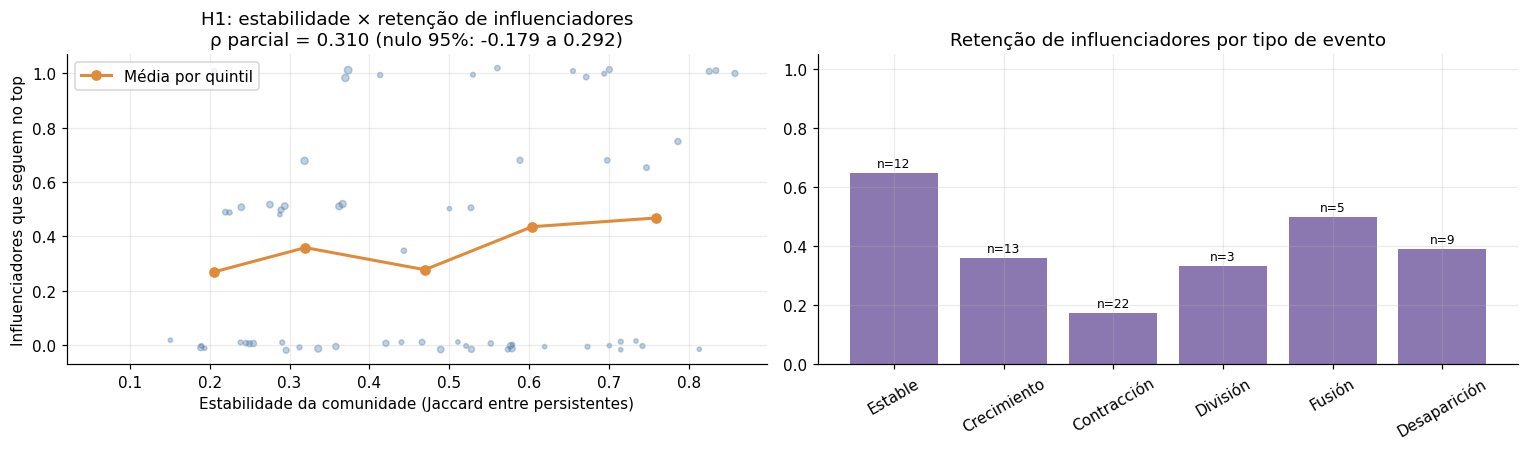

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
if len(con_infl):
    axes[0].scatter(con_infl.estabilidad, con_infl.retencion_influenciadores + rng_global.uniform(-0.02, 0.02, len(con_infl)),
                    s=np.clip(con_infl.tamano / 5, 8, 120), alpha=0.35, color=AZUL)
    if len(con_infl) >= 5:
        axes[0].plot(resumen_quintiles.estabilidad_media, resumen_quintiles.retencion_influenciadores, "o-", color=NARANJA, lw=2,
                     label="Média por quintil")
        axes[0].legend()
axes[0].set(title=f"H1: estabilidade × retenção de influenciadores\nρ parcial = {h1.rho_parcial[0]:.3f} "
                  f"(nulo 95%: {h1.nulo_p2_5[0]:.3f} a {h1.nulo_p97_5[0]:.3f})",
            xlabel="Estabilidade da comunidade (Jaccard entre persistentes)", ylabel="Influenciadores que seguem no top")
por_tipo = (comunidades_todas.groupby("tipo_evento").agg(retencion=("retencion_influenciadores", "mean"),
                                                         n=("retencion_influenciadores", "count"))
            .reindex([t for t in ORDEN_EVENTOS if t != "Aparición"]).dropna())
barras = axes[1].bar(por_tipo.index, por_tipo.retencion, color=LILA)
axes[1].bar_label(barras, labels=[f"n={int(n)}" for n in por_tipo.n], padding=2, fontsize=8)
axes[1].set(title="Retenção de influenciadores por tipo de evento", ylim=(0, 1.05)); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); guardar_figura(fig, "fig09_h1_comunidades"); plt.show()

## 14. H3 — Tipo de evento y cambio de importancia

Dos pruebas pareadas por transición (Wilcoxon sobre las medianas de cada transición):

- **H3a:** usuarios cuya comunidad **desaparece** (sin sucesor) vs. usuarios cuya comunidad **continúa** (cualquier evento con sucesor).
- **H3b:** eventos **estructurales** (división, fusión, reorganización) vs. **continuaciones** 1→1. Solo se evalúa si hay suficientes eventos.

Comparamos el cambio de posición global de los usuarios persistentes según el evento de su comunidad en *t*. Para que las transiciones grandes no dominen, primero calculamos la mediana **por transición** y después resumimos entre transiciones. También reportamos el cambio en el percentil de betweenness (con signo), que indica si los usuarios ganan o pierden posición de intermediación.

,transiciones,usuarios,mediana_abs_delta_log_pr,mediana_abs_delta_influenciadores,mediana_delta_pct_betweenness
tipo_evento,,,,,
Estable,11,"1,469",0.1206,0.0965,-0.0009
Crecimiento,11,"1,661",0.1177,0.15,-0.0032
Contracción,10,"1,923",0.1234,0.1588,-0.0023
División,7,638,0.1183,0.2884,-0.0011
Fusión,6,665,0.123,0.0799,-0.0047
Desaparición,9,617,0.1316,0.1698,-0.0069


H3a (desaparece − continúa): {'transiciones': 9, 'diferencia_mediana': -0.0085, 'transiciones_a_mayor': 2, 'p_wilcoxon': np.float64(0.3008)}
H3b (estructural − continuación): {'transiciones': 8, 'diferencia_mediana': 0.0015, 'transiciones_a_mayor': 5, 'p_wilcoxon': np.float64(0.7422)}


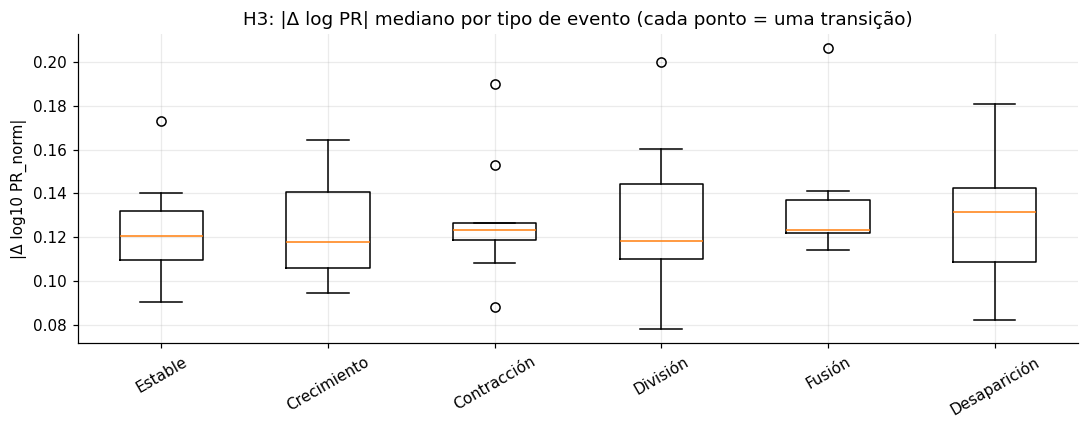

In [24]:
validos = usuarios_todos.loc[usuarios_todos.robusta_a]
por_evento = (validos.groupby(["transicion", "tipo_evento"])
              .agg(usuarios=("usuario", "size"), abs_delta_log_pr=("abs_delta_log_pr", "median"),
                   delta_pct_betweenness=("delta_pct_betweenness", "median"),
                   abs_delta_log_pr_influenciadores=("abs_delta_log_pr", lambda x: x[validos.loc[x.index, "influenciador_a"]].median()))
              .reset_index())
h3 = (por_evento.groupby("tipo_evento")
      .agg(transiciones=("transicion", "nunique"), usuarios=("usuarios", "sum"),
           mediana_abs_delta_log_pr=("abs_delta_log_pr", "median"),
           mediana_abs_delta_influenciadores=("abs_delta_log_pr_influenciadores", "median"),
           mediana_delta_pct_betweenness=("delta_pct_betweenness", "median"))
      .reindex([t for t in ORDEN_EVENTOS + ["Sin evento"] if t != "Aparición"]).dropna(how="all"))
display(h3.round(4))

from scipy.stats import wilcoxon

def prueba_pareada(datos, clasificar, grupo_a, grupo_b):
    grupo = datos.tipo_evento.map(clasificar)
    pareado = (datos.assign(grupo=grupo).dropna(subset=["grupo"])
               .groupby(["transicion", "grupo"]).abs_delta_log_pr.median().unstack())
    if not {grupo_a, grupo_b} <= set(pareado.columns):
        return {"transiciones": 0, "diferencia_mediana": np.nan, "transiciones_a_mayor": np.nan, "p_wilcoxon": np.nan}
    pareado = pareado[[grupo_a, grupo_b]].dropna()
    if len(pareado) < 5:
        return {"transiciones": len(pareado), "diferencia_mediana": np.nan, "transiciones_a_mayor": np.nan, "p_wilcoxon": np.nan}
    d = pareado[grupo_a] - pareado[grupo_b]
    return {"transiciones": len(pareado), "diferencia_mediana": d.median(),
            "transiciones_a_mayor": int((d > 0).sum()), "p_wilcoxon": wilcoxon(d).pvalue}

CONTINUA = {"Estable", "Crecimiento", "Contracción", "División", "Fusión", "Reorganización"}
h3a = prueba_pareada(validos, lambda t: "desaparece" if t == "Desaparición" else "continúa" if t in CONTINUA else None,
                     "desaparece", "continúa")
h3b = prueba_pareada(validos, lambda t: "estructural" if t in ("División", "Fusión", "Reorganización")
                     else "continuación" if t in ("Estable", "Crecimiento", "Contracción") else None,
                     "estructural", "continuación")
print("H3a (desaparece − continúa):", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in h3a.items()})
print("H3b (estructural − continuación):", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in h3b.items()})

fig, ax = plt.subplots(figsize=(10, 4))
tipos = [t for t in h3.index if t in por_evento.tipo_evento.unique()]
ax.boxplot([por_evento.loc[por_evento.tipo_evento.eq(t), "abs_delta_log_pr"].dropna() for t in tipos])
ax.set_xticks(range(1, len(tipos) + 1), tipos)
ax.set(title="H3: |Δ log PR| mediano por tipo de evento (cada ponto = uma transição)", ylabel="|Δ log10 PR_norm|")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); guardar_figura(fig, "fig10_h3_eventos"); plt.show()

## 15. Estudios de caso (ilustrativos, elegidos con un criterio explícito)

- **Linaje más longevo** (desempate: mayor tamaño medio): tamaño en el tiempo y trayectoria **global** de sus 3 principales influenciadores.
- **Mayor división y mayor fusión** (por número de usuarios): flujo de usuarios persistentes entre comunidades (Sankey).

No son casos "representativos"; ilustran los resultados agregados de las secciones 12–14.

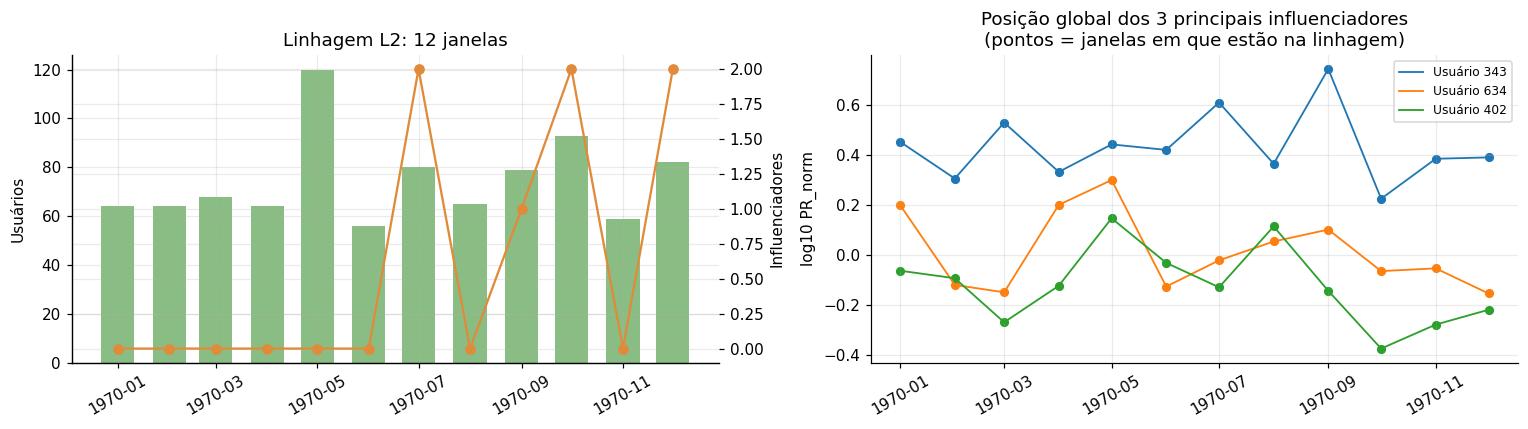

In [25]:
linaje_caso = vida.sort_values(["duracion", "tamano_medio"], ascending=False).index[0]
serie = linajes.loc[linajes.linaje.eq(linaje_caso)]
miembros_linaje = []
for r in serie.itertuples():
    imp = resultados[r.ventana]["imp"]
    miembros_linaje.append(imp.loc[imp.comunidad.eq(r.comunidad), ["usuario", "log_pr"]].assign(ventana=r.ventana))
miembros_linaje = pd.concat(miembros_linaje)
# Principales: usuarios presentes en más ventanas del linaje; desempate por PageRank medio.
principales = (miembros_linaje.groupby("usuario").agg(ventanas=("ventana", "size"), pr=("log_pr", "mean"))
               .sort_values(["ventanas", "pr"], ascending=False).head(3).index)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(serie.inicio, serie.tamano, width=20 * DURACION, color=VERDE, alpha=0.7, label="Usuários")
ax2 = axes[0].twinx(); ax2.plot(serie.inicio, serie.influenciadores, "o-", color=NARANJA, label="Influenciadores")
axes[0].set(title=f"Linhagem L{linaje_caso}: {len(serie)} janelas", ylabel="Usuários"); ax2.set_ylabel("Influenciadores")
axes[0].tick_params(axis="x", rotation=30)
fechas = [r["info"]["inicio"] for r in resultados]
comunidad_del_linaje = dict(zip(serie.ventana, serie.comunidad))
tablas_por_ventana = [r["imp"].set_index("usuario") for r in resultados]
for usuario in principales:
    trayectoria = [tb.log_pr.get(usuario, np.nan) for tb in tablas_por_ventana]
    dentro = [comunidad_del_linaje.get(v, -1) == tb.comunidad.get(usuario, -2) for v, tb in enumerate(tablas_por_ventana)]
    linea, = axes[1].plot(fechas, trayectoria, "-", lw=1.2, label=f"Usuário {usuario}")
    axes[1].scatter([f for f, d in zip(fechas, dentro) if d], [v for v, d in zip(trayectoria, dentro) if d], color=linea.get_color(), s=25)
axes[1].set(title="Posição global dos 3 principais influenciadores\n(pontos = janelas em que estão na linhagem)",
            ylabel="log10 PR_norm"); axes[1].legend(fontsize=8); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); guardar_figura(fig, "fig11_caso_linaje"); plt.show()

In [26]:
def sankey_evento(fila):
    t = int(fila.transicion); A, B = resultados[t], resultados[t + 1]
    a = A["asig"][["usuario", "comunidad"]]; b = B["asig"][["usuario", "comunidad"]]
    involucrados_a = a.loc[a.comunidad.isin(fila.comunidades_a)]
    flujo = involucrados_a.merge(b, on="usuario", how="left", suffixes=("_a", "_b"))
    flujo["destino"] = np.where(flujo.comunidad_b.isna(), "Inativo em t+1",
                         np.where(flujo.comunidad_b.isin(fila.comunidades_b), "C" + flujo.comunidad_b.astype("Int64").astype(str) + " (t+1)", "Outras comunidades"))
    flujo["origen"] = "C" + flujo.comunidad_a.astype(str) + " (t)"
    entrantes = b.loc[b.comunidad.isin(fila.comunidades_b) & ~b.usuario.isin(a.usuario)]
    extra = pd.DataFrame({"origen": "Novos em t+1", "destino": "C" + entrantes.comunidad.astype(str) + " (t+1)"})
    tabla = pd.concat([flujo[["origen", "destino"]], extra]).value_counts().reset_index(name="usuarios")
    try:
        import plotly.graph_objects as go
        nodos = list(dict.fromkeys(tabla.origen.tolist() + tabla.destino.tolist()))
        fig = go.Figure(go.Sankey(node=dict(label=nodos, pad=18, thickness=16),
                                  link=dict(source=tabla.origen.map(nodos.index), target=tabla.destino.map(nodos.index),
                                            value=tabla.usuarios, color="rgba(120,140,170,0.35)")))
        fig.update_layout(title=f"{fila.tipo}: {resultados[t]['info']['inicio']:%Y-%m} → {resultados[t + 1]['info']['inicio']:%Y-%m}", height=450)
        fig.write_html(FIGURAS / f"sankey_{fila.tipo.lower()}.html"); fig.show()
    except ImportError:
        display(tabla)
    return tabla

for tipo in ["División", "Fusión"]:
    candidatos = eventos_comunidades.loc[eventos_comunidades.tipo.eq(tipo)]
    if len(candidatos):
        caso = candidatos.sort_values("usuarios_a", ascending=False).iloc[0]
        print(f"{tipo} mayor: transición {caso.transicion}, {caso.comunidades_a} → {caso.comunidades_b}")
        sankey_evento(caso)
    else:
        print(f"No se encontraron eventos de tipo {tipo} con los criterios actuales.")

División mayor: transición 0, [0] → [0, 8]


Fusión mayor: transición 10, [1, 5, 6] → [0]


## 16. Sensibilidad

Comprobamos si las conclusiones dependen de decisiones arbitrarias:

1. **Umbral de cobertura** de los eventos (0,3–0,6).
2. **Definición de influenciador** (top 0,5 %, 1 %, 5 %).
3. **Usuarios atípicos excluidos** (≥ 1 % de los eventos) y, en WikiTalk, el análisis **con** bots, repitiendo el núcleo del análisis.
4. **Filtro de actividad** (mínimo 1 participación) si `SENSIBILIDAD_SIN_FILTRO = True`. Es costoso en redes grandes.

In [27]:
filas = []
for umbral in [0.3, 0.4, 0.5, 0.6]:
    for t, tr in enumerate(transiciones):
        _, ev, _ = identificar_eventos(tr["pares"], resultados[t]["com"], resultados[t + 1]["com"], tr["pers_a"], umbral)
        for tipo, n in ev.tipo.value_counts().items():
            filas.append({"umbral": umbral, "tipo": tipo, "eventos": n})
sens_umbral = pd.DataFrame(filas).groupby(["umbral", "tipo"]).eventos.sum().unstack(fill_value=0).reindex(columns=ORDEN_EVENTOS, fill_value=0)
display(sens_umbral)

rng = np.random.default_rng(SEMILLA_GENERAL)
sens_influenciadores = pd.DataFrame([
    {"top_%": 100 * f, **h1_agregado(pd.concat([tabla_comunidades(t, tr, f) for t, tr in enumerate(transiciones)]),
                                    max(100, N_PERMUTACIONES // 2), rng)}
    for f in [0.005, 0.01, 0.05]])
display(sens_influenciadores.round(4))

tipo,Estable,Crecimiento,Contracción,División,Fusión,Reorganización,Aparición,Desaparición
umbral,,,,,,,,
0.3,29,26,16,7,7,18,2,2
0.4,31,35,28,13,12,3,9,9
0.5,31,42,33,9,9,0,14,14
0.6,29,36,34,5,7,0,31,30


,top_%,comunidades,rho_parcial,nulo_p2_5,nulo_p97_5,p_valor
0,0.5,64,0.3096,-0.1545,0.2839,0.0198
1,1,64,0.3096,-0.181,0.287,0.0297
2,5,123,0.0932,-0.1251,0.2134,0.2871


In [28]:
def nucleo(datos, nombre, semillas):
    """Repite el núcleo (ventanas, comunidades, PageRank, H1 y H2) con otra base de eventos."""
    global resultados
    guardado = resultados
    try:
        resultados = procesar_ventanas(datos, VENTANAS, semillas, betweenness=False, mensajes=False)
        trs = [analizar_transicion(resultados[t], resultados[t + 1], UMBRAL_COBERTURA) for t in range(len(resultados) - 1)]
        r = np.random.default_rng(SEMILLA_GENERAL)
        rhos = []
        for t, tr in enumerate(trs):
            res = h2_transicion(tabla_usuarios(t, tr), max(50, N_PERMUTACIONES // 4), r)
            rhos.append(res)
        rhos = pd.DataFrame(rhos)
        com = pd.concat([tabla_comunidades(t, tr) for t, tr in enumerate(trs)])
        h1r = h1_agregado(com, max(100, N_PERMUTACIONES // 2), r)
        h1y2 = h1_agregado(com, max(100, N_PERMUTACIONES // 2), r, "mediana_abs_delta_log_pr")
        eventos = pd.concat([tr["eventos"] for tr in trs]).tipo.value_counts()
        return {"configuracion": nombre, "H1_rho_parcial": h1r["rho_parcial"], "H1_p": h1r["p_valor"],
                "H1Y2_rho_parcial": h1y2["rho_parcial"], "H1Y2_p": h1y2["p_valor"],
                "H2_rho_mediano": rhos.rho_parcial.median(),
                "H2_pct_transiciones_fuera_nulo": 100 * ((rhos.rho_parcial < rhos.nulo_p2_5) | (rhos.rho_parcial > rhos.nulo_p97_5)).mean(),
                "H2v_rho_mediano": rhos.rho_parcial_vecinos.median(),
                "H2v_pct_transiciones_fuera_nulo": 100 * ((rhos.rho_parcial_vecinos < rhos.nulo_v_p2_5) | (rhos.rho_parcial_vecinos > rhos.nulo_v_p97_5)).mean(),
                "eventos_division": int(eventos.get("División", 0)), "eventos_fusion": int(eventos.get("Fusión", 0)),
                "continuaciones": int(sum(eventos.get(k, 0) for k in ["Estable", "Crecimiento", "Contracción"]))}
    finally:
        resultados = guardado

inicio_etapa = time.perf_counter()
sensibilidad = [{"configuracion": "Principal",
                 "H1_rho_parcial": h1.rho_parcial[0], "H1_p": h1.p_valor[0],
                 "H1Y2_rho_parcial": h1.rho_parcial[1], "H1Y2_p": h1.p_valor[1],
                 "H2_rho_mediano": h2.rho_parcial.median(), "H2_pct_transiciones_fuera_nulo": 100 * h2.fuera_del_nulo.mean(),
                 "H2v_rho_mediano": h2.rho_parcial_vecinos.median(), "H2v_pct_transiciones_fuera_nulo": 100 * h2.fuera_del_nulo_vecinos.mean(),
                 "eventos_division": int(conteo_eventos["División"]), "eventos_fusion": int(conteo_eventos["Fusión"]),
                 "continuaciones": int(conteo_eventos[["Estable", "Crecimiento", "Contracción"]].sum())}]
sensibilidad.append(nucleo(datos_limpios, f"Semillas alternativas {SEMILLAS_ALTERNATIVAS}", SEMILLAS_ALTERNATIVAS))
if USUARIOS_EXCLUIR_SENSIBILIDAD:
    sin_atipicos = filtrar_actividad(base_analisis.loc[~base_analisis.source.isin(USUARIOS_EXCLUIR_SENSIBILIDAD)
                                                       & ~base_analisis.target.isin(USUARIOS_EXCLUIR_SENSIBILIDAD)],
                                     MINIMO_PARTICIPACIONES)
    sensibilidad.append(nucleo(sin_atipicos, f"Sin {len(USUARIOS_EXCLUIR_SENSIBILIDAD)} usuario(s) atípico(s)", SEMILLAS_ALTERNATIVAS))
if EXCLUIR_BOTS and bots:
    sensibilidad.append(nucleo(filtrar_actividad(base_con_bots, MINIMO_PARTICIPACIONES), f"Con los {len(bots)} bots", SEMILLAS_ALTERNATIVAS))
if SENSIBILIDAD_SIN_FILTRO:
    sensibilidad.append(nucleo(filtrar_actividad(base_analisis, 1), "Sin filtro de actividad (mínimo 1)", SEMILLAS_ALTERNATIVAS))
sensibilidad = pd.DataFrame(sensibilidad)
tiempos["sensibilidad"] = time.perf_counter() - inicio_etapa
display(sensibilidad.round(4))

,configuracion,H1_rho_parcial,H1_p,H1Y2_rho_parcial,H1Y2_p,H2_rho_mediano,H2_pct_transiciones_fuera_nulo,H2v_rho_mediano,H2v_pct_transiciones_fuera_nulo,eventos_division,eventos_fusion,continuaciones
0,Principal,0.3096,0.0199,-0.122,0.1791,-0.038,18.1818,-0.0084,9.0909,9,9,106
1,"Semillas alternativas [3, 11, 2024]",0.3788,0.0099,-0.1251,0.099,-0.0428,27.2727,-0.0217,18.1818,6,7,108
2,Sin filtro de actividad (mínimo 1),0.3635,0.0099,-0.1317,0.2178,-0.0411,27.2727,-0.0053,18.1818,8,9,103


## 17. Respuesta a la pregunta del proyecto

La regla de decisión es explícita y se fija antes de mirar los resultados:

- **Evidencia de asociación:** el ρ observado está fuera del intervalo nulo del 95 %, en la dirección esperada, y la conclusión se mantiene en la sensibilidad.
- **Evidencia débil:** hay dirección esperada y significancia en el análisis principal, pero no se mantiene en todas las variantes.
- **Sin evidencia:** el ρ observado cae dentro del nulo.

El texto en portugués de abajo se genera con los números de esta ejecución para adaptarlo al informe. Revísenlo antes de copiarlo. Los valores p con 100 permutaciones tienen mínimo ≈ 0,01: repórtenlos como *p* < 0,01.

In [29]:
def veredicto(rho, p_inf, p_sup, signo, robusto):
    if np.isnan(rho):
        return "não avaliável"
    fuera = rho < p_inf or rho > p_sup
    direccion = np.sign(rho) == signo
    if fuera and direccion and robusto:
        return "evidência de associação"
    if fuera and direccion:
        return "evidência fraca (não robusta)"
    if fuera:
        return "associação no sentido oposto ao esperado"
    return "sem evidência (dentro do nulo)"

def robusto(col_rho, col_crit, signo, es_p=True):
    r, c = sensibilidad[col_rho], sensibilidad[col_crit]
    ok = r.notna() & c.notna()
    if not ok.any():
        return False
    criterio = (c[ok] < 0.05) if es_p else (c[ok] >= 50)
    return bool((np.sign(r[ok]) == signo).all() and criterio.all())

def veredicto_test(diferencia, p, esperado="maior"):
    if np.isnan(p):
        return "não avaliável (poucos dados)"
    if p < 0.05:
        return f"evidência de mudança {'maior' if diferencia > 0 else 'menor'} no primeiro grupo"
    return "sem evidência de diferença"

def fmt_p(p):
    return "—" if np.isnan(p) else ("< 0,01" if p <= 0.0100 else f"{p:.3f}")

h2_resumen = {"rho": h2.rho_parcial.median(), "inf": h2.nulo_p2_5.median(), "sup": h2.nulo_p97_5.median()}
h2v_resumen = {"rho": h2.rho_parcial_vecinos.median(), "inf": h2.nulo_v_p2_5.median(), "sup": h2.nulo_v_p97_5.median()}

respuestas = pd.DataFrame([
    {"hipótese": "H1-Y1 (comunidade)", "estatística": "ρ parcial: estabilidade × retenção de influenciadores no topo",
     "observado": h1.rho_parcial[0], "nulo_95%": f"[{h1.nulo_p2_5[0]:.3f}, {h1.nulo_p97_5[0]:.3f}]", "p": fmt_p(h1.p_valor[0]),
     "veredito": veredicto(h1.rho_parcial[0], h1.nulo_p2_5[0], h1.nulo_p97_5[0], +1,
                           robusto("H1_rho_parcial", "H1_p", +1))},
    {"hipótese": "H1-Y2 (comunidade)", "estatística": "ρ parcial: estabilidade × |Δ log PR| mediano dos membros",
     "observado": h1.rho_parcial[1], "nulo_95%": f"[{h1.nulo_p2_5[1]:.3f}, {h1.nulo_p97_5[1]:.3f}]", "p": fmt_p(h1.p_valor[1]),
     "veredito": veredicto(h1.rho_parcial[1], h1.nulo_p2_5[1], h1.nulo_p97_5[1], -1,
                           robusto("H1Y2_rho_parcial", "H1Y2_p", -1))},
    {"hipótese": "H2a (usuário)", "estatística": "ρ parcial mediano s_u × |Δ log PR| | grau",
     "observado": h2_resumen["rho"], "nulo_95%": f"[{h2_resumen['inf']:.3f}, {h2_resumen['sup']:.3f}]",
     "p": f"fora do nulo em {100 * h2.fuera_del_nulo.mean():.0f}% das transições",
     "veredito": veredicto(h2_resumen["rho"], h2_resumen["inf"], h2_resumen["sup"], -1,
                           robusto("H2_rho_mediano", "H2_pct_transiciones_fuera_nulo", -1, es_p=False))},
    {"hipótese": "H2b (usuário)", "estatística": "ρ parcial mediano s_u × |Δ log PR| | grau + vizinhos diretos",
     "observado": h2v_resumen["rho"], "nulo_95%": f"[{h2v_resumen['inf']:.3f}, {h2v_resumen['sup']:.3f}]",
     "p": f"fora do nulo em {100 * h2.fuera_del_nulo_vecinos.mean():.0f}% das transições",
     "veredito": veredicto(h2v_resumen["rho"], h2v_resumen["inf"], h2v_resumen["sup"], -1,
                           robusto("H2v_rho_mediano", "H2v_pct_transiciones_fuera_nulo", -1, es_p=False))},
    {"hipótese": "H3a (evento)", "estatística": "|Δ log PR|: comunidade desaparece − continua (pareado por transição)",
     "observado": h3a["diferencia_mediana"], "nulo_95%": "Wilcoxon", "p": fmt_p(h3a["p_wilcoxon"]),
     "veredito": veredicto_test(h3a["diferencia_mediana"], h3a["p_wilcoxon"])},
    {"hipótese": "H3b (evento)", "estatística": "|Δ log PR|: divisão/fusão − continuação 1→1 (pareado por transição)",
     "observado": h3b["diferencia_mediana"], "nulo_95%": "Wilcoxon", "p": fmt_p(h3b["p_wilcoxon"]),
     "veredito": veredicto_test(h3b["diferencia_mediana"], h3b["p_wilcoxon"])},
])
display(respuestas)
respuestas.to_csv(CARPETA / "respuesta_hipotesis.csv", index=False)

ei = estabilidad_influenciadores; pa = participacion
texto = f"""
Na {NOMBRE_RED} ({INICIO:%Y-%m}–{(FIN - pd.Timedelta(days=1)):%Y-%m}, janelas de {DURACION} mês(es), {len(VENTANAS)} janelas),
a retenção mediana de usuários entre janelas foi de {100 * pd.Series([len(tr['comunes']) / len(resultados[t]['asig']) for t, tr in enumerate(transiciones)]).median():.1f}%
e o ARI temporal mediano (usuários persistentes) foi {comparacion_ventanas.set_index('duracion_meses').ari_temporal_mediano.get(DURACION, np.nan):.3f}.
Foram identificadas {int(conteo_eventos[['Estable', 'Crecimiento', 'Contracción']].sum())} continuações,
{int(conteo_eventos['División'])} divisões, {int(conteo_eventos['Fusión'])} fusões, {int(conteo_eventos['Reorganización'])} reorganizações,
{int(conteo_eventos['Aparición'])} aparições e {int(conteo_eventos['Desaparición'])} desaparecimentos de comunidades robustas.
A vida mediana das linhagens foi de {vida.duracion.median():.0f} janela(s).

Os influenciadores (top {100 * FRACCION_INFLUENCIADORES:g}% do PageRank global) permaneceram no topo em {ei.pct_top_sigue_top.median():.1f}% dos casos
(mediana entre transições), e a correlação de Spearman do log-PageRank entre janelas consecutivas foi {ei.spearman_logpr_persistentes.median():.2f}.
O coeficiente de participação mediano dos influenciadores foi {pa.participacion_influenciadores.median():.2f},
contra {pa.participacion_resto.median():.2f} dos demais usuários.

H1-Y1: ρ parcial = {h1.rho_parcial[0]:.3f} (nulo 95%: {h1.nulo_p2_5[0]:.3f} a {h1.nulo_p97_5[0]:.3f}; {int(h1.comunidades[0])} comunidades) → {respuestas.veredito[0]}.
H1-Y2: ρ parcial = {h1.rho_parcial[1]:.3f} (nulo 95%: {h1.nulo_p2_5[1]:.3f} a {h1.nulo_p97_5[1]:.3f}) → {respuestas.veredito[1]}.
H2a (controle: grau): ρ parcial mediano = {h2_resumen['rho']:.3f}; fora do nulo em {100 * h2.fuera_del_nulo.mean():.0f}% das transições → {respuestas.veredito[2]}.
H2b (controle: grau + vizinhos diretos): ρ parcial mediano = {h2v_resumen['rho']:.3f}; fora do nulo em {100 * h2.fuera_del_nulo_vecinos.mean():.0f}% das transições → {respuestas.veredito[3]}.
H3a: diferença mediana de |Δ log PR| (comunidade desaparece − continua) = {h3a['diferencia_mediana']:.3f} em {h3a['transiciones']} transições (Wilcoxon p {fmt_p(h3a['p_wilcoxon'])}) → {respuestas.veredito[4]}.
H3b: diferença mediana (divisão/fusão − continuação) = {h3b['diferencia_mediana']:.3f} em {h3b['transiciones']} transições (Wilcoxon p {fmt_p(h3b['p_wilcoxon'])}) → {respuestas.veredito[5]}.
Esses resultados descrevem associações, não relações causais.
"""
print(texto)
(CARPETA / "texto_resultados_pt.txt").write_text(texto, encoding="utf-8")

,hipótese,estatística,observado,nulo_95%,p,veredito
0,H1-Y1 (comunidade),ρ parcial: estabilidade × retenção de influenc...,0.309618,"[-0.179, 0.292]",0.020,evidência de associação
1,H1-Y2 (comunidade),ρ parcial: estabilidade × |Δ log PR| mediano d...,-0.122001,"[-0.203, 0.059]",0.179,sem evidência (dentro do nulo)
2,H2a (usuário),ρ parcial mediano s_u × |Δ log PR| | grau,-0.038028,"[-0.072, 0.081]",fora do nulo em 18% das transições,sem evidência (dentro do nulo)
3,H2b (usuário),ρ parcial mediano s_u × |Δ log PR| | grau + vi...,-0.00843928,"[-0.073, 0.081]",fora do nulo em 9% das transições,sem evidência (dentro do nulo)
4,H3a (evento),|Δ log PR|: comunidade desaparece − continua (...,-0.00849321,Wilcoxon,0.301,sem evidência de diferença
5,H3b (evento),|Δ log PR|: divisão/fusão − continuação 1→1 (p...,0.00152444,Wilcoxon,0.742,sem evidência de diferença



Na email-Eu-core (1970-01–1970-12, janelas de 1 mês(es), 12 janelas),
a retenção mediana de usuários entre janelas foi de 94.2%
e o ARI temporal mediano (usuários persistentes) foi 0.380.
Foram identificadas 106 continuações,
9 divisões, 9 fusões, 0 reorganizações,
14 aparições e 14 desaparecimentos de comunidades robustas.
A vida mediana das linhagens foi de 3 janela(s).

Os influenciadores (top 1% do PageRank global) permaneceram no topo em 40.0% dos casos
(mediana entre transições), e a correlação de Spearman do log-PageRank entre janelas consecutivas foi 0.80.
O coeficiente de participação mediano dos influenciadores foi 0.69,
contra 0.44 dos demais usuários.

H1-Y1: ρ parcial = 0.310 (nulo 95%: -0.179 a 0.292; 64 comunidades) → evidência de associação.
H1-Y2: ρ parcial = -0.122 (nulo 95%: -0.203 a 0.059) → sem evidência (dentro do nulo).
H2a (controle: grau): ρ parcial mediano = -0.038; fora do nulo em 18% das transições → sem evidência (dentro do nulo).
H2b (controle: grau + viz

1446

## 18. Exportar resultados

Se guardan las tablas CSV, las figuras PNG, los GraphML y la configuración (incluido el hash SHA-256 del archivo de entrada) en un ZIP. **Descárguenlo antes de cerrar Colab.**

Para el informe:

- Suban `graphml/` y el ZIP al repositorio o Drive indicado en la entrega.
- Citen la fuente original en SNAP.

In [30]:
tablas = {
    "carga": resumen_carga, "preprocesamiento": resumen_preprocesamiento, "metricas_graphml": tabla_estatica,
    "comparacion_ventanas": comparacion_ventanas, "ventanas": resumen_ventanas, "eventos": eventos_comunidades,
    "linajes": linajes, "vida_linajes": vida.reset_index(), "estabilidad_influenciadores": estabilidad_influenciadores,
    "participacion": participacion, "h1_comunidades": comunidades_todas, "h1": h1, "h2": h2, "h3": h3.reset_index(),
    "sensibilidad_umbral": sens_umbral.reset_index(), "sensibilidad_influenciadores": sens_influenciadores,
    "sensibilidad": sensibilidad, "respuestas": respuestas,
}
if validacion_departamentos is not None:
    tablas["validacion_departamentos"] = validacion_departamentos
for nombre, tabla in tablas.items():
    tabla.to_csv(CARPETA / f"{nombre}.csv", index=False)
usuarios_todos.to_csv(CARPETA / "h2_usuarios.csv.gz", index=False)

configuracion = {
    "red": NOMBRE_RED, "url": URL, "archivo": str(ARCHIVO),
    "sha256": hashlib.sha256(ARCHIVO.read_bytes()).hexdigest(),
    "inicio": str(INICIO), "fin_exclusivo": str(FIN), "minimo_participaciones": MINIMO_PARTICIPACIONES,
    "duracion_ventana_meses": DURACION, "duracion_sugerida": sugerida, "semillas": SEMILLAS,
    "resolucion": RESOLUCION, "minimo_comunidad": MINIMO_COMUNIDAD, "umbral_robustez": UMBRAL_ROBUSTEZ,
    "minimo_compartidos": MINIMO_COMPARTIDOS, "umbral_cobertura": UMBRAL_COBERTURA, "umbral_cambio": UMBRAL_CAMBIO,
    "fraccion_influenciadores": FRACCION_INFLUENCIADORES, "permutaciones": N_PERMUTACIONES,
    "betweenness_muestra": MUESTRA_BETWEENNESS if CALCULAR_BETWEENNESS else None,
    "usuarios_atipicos_sensibilidad": [int(u) for u in USUARIOS_EXCLUIR_SENSIBILIDAD],
    "bots_excluidos": [int(u) for u in bots] if EXCLUIR_BOTS else [],
    "backend": BACKEND, "networkx": nx.__version__, "pandas": pd.__version__, "python": platform.python_version(),
    "tiempos_segundos": {k: round(v, 1) for k, v in tiempos.items()},
}
(CARPETA / "configuracion.json").write_text(json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8")
ruta_zip = shutil.make_archive(str(CARPETA), "zip", CARPETA)
print("Resultados guardados en:", ruta_zip)
print("Tiempos (s):", configuracion["tiempos_segundos"])

Resultados guardados en: /content/resultados_emaileu.zip
Tiempos (s): {'estatico': 74.1, 'tradeoff_ventanas': 4.3, 'ventanas': 6.0, 'h2': 19.7, 'sensibilidad': 18.2}
